# Jin pseudobulk edgeR vs spatial pseudobulk edgeR correlation

Compare aged-versus-adult log2 fold changes using Spearman correlation and directional agreement. Best/worst methods are ranked independently for all common genes and genes significant in both datasets. Run from a fresh kernel; input data and the cellseg_benchmark package must be available.

## 1. Imports and configuration

In [1]:
from pathlib import Path
from functools import lru_cache
from IPython.display import display
from adjustText import adjust_text

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



import seaborn as sns
from cellseg_benchmark._constants import method_colors as original_method_colors
from scipy.stats import spearmanr

sns.set_context("notebook")


method_colors = dict(original_method_colors)

In [2]:
PROJECT_DIR = Path("/dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark")
jin_dea_path = PROJECT_DIR / "misc/Jin_count_data/edgeR_results_primary/all_subclasses_edgeR_results.csv"
analysis_root = PROJECT_DIR / "analysis/aging"
out_path = PROJECT_DIR / "misc/dea"
figure_dir = out_path / "figures_poster"
figure_dir.mkdir(parents=True, exist_ok=True)
dea_filename = "aging-by-celltype_pseudobulk_edgeR_LRT_WT_18vsWT_3.xlsx"

alpha = 0.05
MIN_GENES_FOR_RANKING = 3

# Spatial sheet name -> Jin pseudobulk subclass_label.
# These defaults correspond to the broad labels used in the previous analysis.
# The validation cell below will show immediately if a label needs changing.
cell_type_map = {
    "ECs": "Endo NN",
    "Microglia": "Microglia NN",
    "OPCs": "OPC NN",
    "Pericytes": "Peri NN",
    "SMCs": "SMC NN",
}

cell_types_to_plot = ["ECs", "Pericytes", "SMCs", "OPCs", "Microglia"]

# Optional exclusions from the previous workflow:
exclude_methods = {
    "SIS_DAPI_total_mrna",
    "Watershed_Merlin",
    "Negative_Control_Rastered_5",
    "Negative_Control_Rastered_10",
    "Negative_Control_Rastered_25",
    "Negative_Control_Voronoi",
}

In [3]:
marker_genes = {
      "ECs": [
        "Cldn5",
        "Cdh5",
        "Pecam1",
        "Kdr",
        "Flt1",
        "Tie1",
        "Tek",
        "Nos3",
        "Ocln",
        "Pdgfb",
        "Mgp",
        "Cytl1",
        "Fbln5",
        "Clu",
        "Eln",
        "Bmx",
        "Efnb2",
        "Vegfc",
        "Sema3g",
        "Gkn3",
        "Fbln2",
        "Hey1",
        "Egfl8",
        "Jag1",
        "Igf2",
        "Notch3",
        "Tgfb2",
        "Rad54b",
        "Slc26a10",
        "Slc7a5",
        "Mfsd2a",
        "Tfrc",
        "Slc16a1",
        "Meox1",
        "Col4a3",
        "Angpt2",
        "Rgcc",
        "Cxcl12",
        "Ecscr",
        "Apln",
        "Car4",
        "Slc38a5",
        "Gatm",
        "Itm2a",
        "Flt4",
        "Vwf",
        "Nr2f2",
        "Flrt2",
        "Ier3",
        "Vcam1",
        "Ly6c1",
        "Ly6a",
        "Ctsc",
        "Ackr1",
        "Lcn2",
        "Icam1",
        "Tmem252",
        "Apoe",
        "App",
        "Mfge8",
        "Prdx1",
        "Prdx2",
        "Prdx6",
        "Sod1",
        "Sod2",
        "Ifit1",
        "Depp1",
        "S100a6",
        "Cd9",
        "Hif1a",
        "Notch1",
        "Fscn1",
        "Plvap",
        "Ccn2",
        "Fgfbp1",
        "Bmp6",
        "Bgn",
        "Ly6e",
        "Acer2",
        "B2m",
        "Cxcr4",
        "Pgf",
        "Adamts1",
        "Plaur",
        "Cx3cl1",
        "Arl15",
        "Hsp90aa1",
        "Plpp3",
    ],
    "Pericytes": [
        "Vtn",
        "Kcnj8",
        "Rgs5",
        "Cd248",
        "Atp13a5",
        "Anpep",
        "Higd1b",
        "Flt1",
        "Ecscr",
        "Cd93",
        "Apln",
        "Col4a1",
        "Col4a2",
        "Col4a3",
        "Col4a4",
        "Lama4",
        "Adamts1",
        "Slc20a2",
        "Slc1a3",
        "Slc6a13",
        "Pdgfrb",
        "Pdgfa",
        "Pdgfb",
    ],
    "SMCs": [
        "Acta2",
        "Pdlim3",
        "Tagln",
        "Myh11",
        "Sncg",
        "Cnn1",
        "Pln",
        "Adamts1",
        "Arl4d",
        "Atf3",
        "Cd93",
        "H2afj",
        "Nanos1",
        "Abca1",
        "AI593442",
        "Car4",
        "Col6a2",
    ],
    "Pericytes_SMCS": ["Pdgfrb", "Cspg4", "Abcc9", "Anpep"],
    "Microglia": [
        "Cx3cr1",
        "Ctss",
        "Tmem119",
        "P2ry12",
        "Itgam",
        "Csf1r",
        "Laptm5",
        "Lyz2",
        "Itgax",
        "Axl",
        "Spp1",
        "Trem2",
        "Apoe",
        "Lgals3",
        "Lpl",
        "Cd74",
        "H2-Aa",
        "Ccl4",
        "Ccl3",
        "B2m",
        "Cd9",
        "C1qa",
        "C1qc",
        "Dpp10",
        "Meg3",
    ],
    "Microglia_Macrophages": [
        "Trem2",
        "Cx3cr1",
        "Aif1",
        "Itgam",
        "Itgax",
        "C1qc",
        "Ctss",
        "C1qa",
        "Csf1r",
        "Laptm5",
        "B2m",
        "P2ry12",
        "Mrc1",
    ], "Oligodendrocytes_OPCs": [
        "Plp1",
        "Cnp",
        "Cldn11",
        "Mbp",
        "Mag",
        "Mog",
        "Enpp2",
        "Trf",
        "Apod",
        "Plxnb3",
        "Olig2",
        "Enpp6",
        "Olig1",
        "Opalin",
        "Bmp4",
        "Klk6",
        "Vcan",
        "Prox1",
        "C4b",
        "Il33",
        "Il18",
        "Tcf7l2",
        "Cemip2",
        "Pdgfa",
        "Ctps",
        "S100b",
        "Pdgfra",
        "Vim",
        "Eno2",
        "Serpina3n",
        "Plvap",
        "Cdkn1a",
        "Klf4",
        "Stat1",
        "Ifit1",
        "Ptprz1",
        "Pdgfra",
        "Cspg4",
        "Olig1",
        "Cspg5",
        "Rgcc",
        "Olig2",
        "Vcan",
        "Cd9",
        "Sox10",
        "Apod",
        "Nkx2-2",
        "Bmp4",
    ]
}

In [4]:
method_colors["Proseg_3D_Cellpose_1_DAPI_PolyT"] = "#d1c9b4"
method_colors["Proseg_3D_Cellpose_1_DAPI_Transcripts"] = "#d6c9a9"

In [5]:
method_display_names = {

    # --------------------------------------------------------------
    # Baysor
    # --------------------------------------------------------------

    "Baysor_2D_Cellpose_1_DAPI_PolyT_0.2":
        "Baysor_CP1P_0.2",

    "Baysor_2D_Cellpose_1_DAPI_PolyT_0.8":
        "Baysor_CP1P_0.8",

    "Baysor_2D_Cellpose_1_DAPI_Transcripts_0.2":
        "Baysor_CP1T_0.2",

    "Baysor_2D_Cellpose_1_DAPI_Transcripts_0.8":
        "Baysor_CP1T_0.8",

    "Baysor_2D_Cellpose_1_nuclei_model_1.0":
        "Baysor_CP1n_1.0",

    "Baysor_2D_Cellpose_2_DAPI_PolyT_0.2":
        "Baysor_CP2P_0.2",

    "Baysor_2D_Cellpose_2_DAPI_PolyT_0.8":
        "Baysor_CP2P_0.8",

    "Baysor_2D_Cellpose_2_DAPI_Transcripts_0.2":
        "Baysor_CP2T_0.2",

    "Baysor_2D_Cellpose_2_DAPI_Transcripts_0.8":
        "Baysor_CP2T_0.8",


    # --------------------------------------------------------------
    # Cellpose
    # --------------------------------------------------------------

    "Cellpose_1_DAPI_PolyT":
        "Cellpose_1P",

    "Cellpose_1_DAPI_Transcripts":
        "Cellpose_1T",

    "Cellpose_1_Merlin":
        "Cellpose_1_Merscope",

    "Cellpose_1_nuclei_model":
        "Cellpose_1n",

    "Cellpose_2_DAPI_PolyT":
        "Cellpose_2P",

    "Cellpose_2_DAPI_Transcripts":
        "Cellpose_2T",


    # --------------------------------------------------------------
    # Proseg
    # --------------------------------------------------------------

    "Proseg_3D_Cellpose_1_DAPI_PolyT":
        "Proseg_3D_CP1P",

    "Proseg_3D_Cellpose_1_DAPI_Transcripts":
        "Proseg_3D_CP1T",

    "Proseg_3D_Cellpose_1_nuclei_model":
        "Proseg_3D_CP1n",

    "Proseg_3D_Cellpose_2_DAPI_PolyT":
        "Proseg_3D_CP2P",


    # --------------------------------------------------------------
    # VPT 2D
    # --------------------------------------------------------------

    "vpt_2D_DAPI_PolyT":
        "Cellpose_1P_2D_VPT",

    "vpt_2D_DAPI_PolyT_nuclei":
        "Cellpose_1nP_2D_VPT",

    "vpt_2D_DAPI_nuclei":
        "Cellpose_1n_2D_VPT",


    # --------------------------------------------------------------
    # VPT 3D
    # --------------------------------------------------------------

    "vpt_3D_DAPI_PolyT":
        "Cellpose_1P_3D_VPT",

    "vpt_3D_DAPI_PolyT_nuclei":
        "Cellpose_1nP_3D_VPT",

    "vpt_3D_DAPI_nuclei":
        "Cellpose_1n_3D_VPT",
}


def display_method(method):
    """Return short display name if available."""
    return method_display_names.get(method, method)

## 2. Discover methods and validate Jin results

In [6]:
def get_methods():
    methods = []

    for path in analysis_root.iterdir():
        if not path.is_dir():
            continue

        if path.name.startswith("."):
            continue

        if path.name in exclude_methods:
            continue

        dea_file = path / "dea" / dea_filename

        if dea_file.exists():
            methods.append(path.name)

    return sorted(methods)

def get_method_palette(methods):
    # Use the established palette when available, otherwise a fallback palette.
    fallback = dict(
        zip(methods, sns.color_palette("husl", n_colors=len(methods)))
    )
    if "method_colors" in globals():
        return {
            method: method_colors.get(method, fallback[method])
            for method in methods
        }
    return fallback


methods = get_methods()
print(f"{len(methods)} segmentation methods found")
methods


if not methods:
    raise ValueError("No spatial DEA files found")

25 segmentation methods found


In [7]:
jin_dea = pd.read_csv(jin_dea_path)

required_jin = {"gene", "subclass_label", "logFC", "FDR"}
missing = required_jin - set(jin_dea.columns)
if missing:
    raise ValueError(f"Missing required Jin columns: {sorted(missing)}")

jin_dea = jin_dea[
    ["gene", "subclass_label", "logFC", "FDR"]
].copy()

jin_dea = jin_dea.dropna(
    subset=["gene", "subclass_label", "logFC"]
)

dup = jin_dea.duplicated(["gene", "subclass_label"], keep=False)
print("Jin shape:", jin_dea.shape)
print("Duplicated gene × subclass rows:", int(dup.sum()))
if dup.any():
    display(
        jin_dea.loc[dup]
        .sort_values(["subclass_label", "gene"])
        .head(30)
    )
    raise ValueError(
        "Jin results are not unique by gene × subclass_label."
    )

print("\nAvailable Jin subclass labels:")
print(sorted(jin_dea["subclass_label"].unique()))

Jin shape: (1218995, 4)
Duplicated gene × subclass rows: 0

Available Jin subclass labels:
['AVPV-MEPO-SFO_Tbr1_Glut', 'Astro-NT_NN', 'Astro-TE_NN', 'BAM_NN', 'CA1-ProS_Glut', 'CA3_Glut', 'CS-PRNr-DR_En1_Sox2_Gaba', 'CS-PRNr-PCG_Tmem163_Otp_Gaba', 'CS-RPO_Meis2_Gaba', 'CUN_Evx2_Lhx2_Glut', 'DG_Glut', 'DTN-LDT-IPN_Otp_Pax3_Gaba', 'Endo_NN', 'Ependymal_NN', 'HPF_CR_Glut', 'IC_Six3_En2_Gaba', 'IF-RL-CLI-PAG_Foxa1_Glut', 'IPN-LDT_Vsx2_Nkx6-1_Glut', 'IPN_Otp_Crisp1_Gaba', 'IT_EP-CLA_Glut', 'L2_3_IT_CTX_Glut', 'L2_3_IT_RSP_Glut', 'L4_5_IT_CTX_Glut', 'L5_6_IT_TPE-ENT_Glut', 'L5_ET_CTX_Glut', 'L5_IT_CTX_Glut', 'L5_NP_CTX_Glut', 'L6_CT_CTX_Glut', 'L6_IT_CTX_Glut', 'LDT-DTN_Gata3_Nfix_Gaba', 'LDT-PCG-CS_Gata3_Lhx1_Gaba', 'LDT-PCG_St18_Gaba', 'LDT-PCG_Vsx2_Lhx4_Glut', 'LDT_Fgf7_Gaba', 'LDT_Vsx2_Nkx6-1_Nfib_Glut', 'Lamp5_Gaba', 'Lamp5_Lhx6_Gaba', 'MB-MY_Tph2_Glut-Sero', 'MPN-MPO-PVpo_Hmx2_Glut', 'MRN-PPN-CUN_Pax8_Gaba', 'MRN-VTN-PPN_Pax5_Cdh23_Gaba', 'Microglia_NN', 'NI-RPO_Gata3_Nr4a2_Gaba', 'OB-

In [8]:
# Accept legacy underscore labels only when the original label is absent.
for cell_type, label in cell_type_map.items():
    legacy = label.replace(" ", "_")
    labels = set(jin_dea["subclass_label"])
    if label in labels and legacy in labels:
        raise ValueError(f"Ambiguous Jin labels: {label}, {legacy}")
    if label not in labels and legacy in labels:
        cell_type_map[cell_type] = legacy
# Validate the requested mapping before running all methods.
available_jin_labels = set(jin_dea["subclass_label"].unique())

missing_labels = {
    spatial_ct: jin_ct
    for spatial_ct, jin_ct in cell_type_map.items()
    if jin_ct not in available_jin_labels
}

if missing_labels:
    print("These cell_type_map values are not present in Jin:")
    print(missing_labels)
    print("\nUpdate cell_type_map using the available labels printed above.")
else:
    print("cell_type_map validated.")

cell_type_map validated.


In [9]:
@lru_cache(maxsize=None)
def load_jin_dea(cell_type):
    """
    Select Jin pseudobulk edgeR results for one broad cell type.

    Parameters
    ----------
    cell_type : str
        Broad spatial cell-type name, e.g.:
        "ECs", "Microglia", "OPCs", "Pericytes", "SMCs"

    Returns
    -------
    pd.DataFrame
        Columns:
        gene, logFC_jin, FDR_jin
    """

    if cell_type not in cell_type_map:
        raise KeyError(
            f"{cell_type!r} not found in cell_type_map. "
            f"Available cell types: {list(cell_type_map)}"
        )

    # Translate broad spatial label to Jin subclass label
    # e.g. "ECs" -> "Endo_NN"
    jin_label = cell_type_map[cell_type]

    jin_sub = jin_dea[
        jin_dea["subclass_label"] == jin_label
    ].copy()

    if jin_sub.empty:
        raise ValueError(
            f"No Jin results found for {cell_type!r} "
            f"(subclass_label={jin_label!r})."
        )

    required = {
        "gene",
        "logFC",
        "FDR",
    }

    missing = required - set(jin_sub.columns)

    if missing:
        raise ValueError(
            f"Jin/{cell_type}: "
            f"missing columns {sorted(missing)}"
        )

    # Keep only columns needed for comparison
    jin_sub = (
        jin_sub[
            ["gene", "logFC", "FDR"]
        ]
        .dropna(
            subset=["gene", "logFC"]
        )
        .copy()
    )

    # Rename before merging with spatial results
    jin_sub = jin_sub.rename(
        columns={
            "logFC": "logFC_jin",
            "FDR": "FDR_jin",
        }
    )

    # Gene should occur only once within the Jin cell type
    dup = jin_sub.duplicated(
        "gene",
        keep=False,
    )

    if dup.any():
        display(
            jin_sub.loc[dup]
            .sort_values("gene")
            .head(30)
        )

        raise ValueError(
            f"Jin/{cell_type}: "
            "result is not unique by gene."
        )

    return jin_sub

## 3. Match genes once per method and cell type

The significant subset requires FDR below alpha in both datasets. Matching remains method-specific. Restart the kernel after changing inputs.

In [10]:
def load_spatial_dea(method, cell_type):
    """
    Load spatial pseudobulk edgeR results for one segmentation method
    and one cell type.
    """
    dea_path = analysis_root / method / "dea" / dea_filename

    if not dea_path.exists():
        raise FileNotFoundError(
            f"Spatial DEA file not found:\n{dea_path}"
        )

    spatial = pd.read_excel(dea_path, sheet_name=cell_type)

    required = {"gene", "logFC", "FDR"}
    missing = required - set(spatial.columns)

    if missing:
        raise ValueError(
            f"{method}/{cell_type}: "
            f"missing spatial columns {sorted(missing)}"
        )

    spatial = (
        spatial[
            ["gene", "logFC", "FDR"]
        ]
        .dropna(
            subset=["gene", "logFC"]
        )
        .copy()
    )

    # Give dataset-specific names before merging
    spatial = spatial.rename(
        columns={
            "logFC": "logFC_spatial",
            "FDR": "FDR_spatial",
        }
    )

    # Each gene should occur only once per cell type / method
    dup = spatial.duplicated(
        "gene",
        keep=False,
    )

    if dup.any():
        display(
            spatial.loc[dup]
            .sort_values("gene")
            .head(30)
        )

        raise ValueError(
            f"{method}/{cell_type}: "
            "spatial result is not unique by gene."
        )

    return spatial


@lru_cache(maxsize=None)
def matched_genes(method, cell_type):
    paired = load_jin_dea(cell_type).merge(
        load_spatial_dea(method, cell_type), on="gene", how="inner", validate="one_to_one"
    )
    return paired.assign(method=method, cell_type=cell_type)


def get_common_genes(method, cell_type, significant_only=False, alpha=0.05):
    paired = matched_genes(method, cell_type)
    if significant_only:
        paired = paired.loc[(paired["FDR_jin"] < alpha) & (paired["FDR_spatial"] < alpha)]
    return paired.copy()

In [11]:
# Validate every comparison before analysis; export failures and stop if any occur.
failures = []
for cell_type in cell_types_to_plot:
    for method in methods:
        try:
            matched_genes(method, cell_type)
        except Exception as exc:
            failures.append(dict(method=method, cell_type=cell_type,
                                 error_type=type(exc).__name__, message=str(exc)))
failed_comparisons = pd.DataFrame(failures, columns=["method", "cell_type", "error_type", "message"])
failed_comparisons.to_csv(out_path / "correlation_failed_comparisons.csv", index=False)
if failures:
    display(failed_comparisons)
    raise RuntimeError("Resolve failed comparisons before proceeding.")

## 4. Correlation analysis and exports

In [12]:
def safe_spearman(x, y):
    """Calculate Spearman correlation safely."""
    x = pd.to_numeric(x, errors="coerce")
    y = pd.to_numeric(y, errors="coerce")
    valid = x.notna() & y.notna()
    x, y = x[valid], y[valid]
    if len(x) < 2 or x.nunique() < 2 or y.nunique() < 2:
        return np.nan, np.nan
    return spearmanr(x, y)


def calculate_method_correlation(method, cell_type, significant_only=False, alpha=0.05):
    """Calculate Jin-vs-spatial correlation and directional agreement for one method."""
    paired = get_common_genes(
        method=method,
        cell_type=cell_type,
        significant_only=significant_only,
        alpha=alpha,
    )
    rho, pvalue = safe_spearman(paired["logFC_jin"], paired["logFC_spatial"])
    matching = np.sign(paired["logFC_jin"]) == np.sign(paired["logFC_spatial"])
    n_genes = len(paired)
    n_matching_genes = int(matching.sum())
    percent_matching_genes = 100 * n_matching_genes / n_genes if n_genes else np.nan
    return {
        "cell_type": cell_type,
        "method": method,
        "correlation": rho,
        "correlation_pvalue": pvalue,
        "n_genes": n_genes,
        "n_matching_genes": n_matching_genes,
        "percent_matching_genes": percent_matching_genes,
    }


def calculate_all_method_correlations(cell_type, significant_only=False, alpha=0.05):
    """Calculate results across all discovered segmentation methods for one cell type."""
    rows = [calculate_method_correlation(method, cell_type, significant_only, alpha)
            for method in methods]
    columns = [
        "cell_type", "method", "correlation", "correlation_pvalue",
        "n_genes", "n_matching_genes", "percent_matching_genes",
    ]
    return pd.DataFrame(rows, columns=columns)

In [13]:
all_raw_results = {}
all_sig_results = {}

for cell_type in cell_types_to_plot:
    print(f"\n===== {cell_type} =====")
    raw_res = calculate_all_method_correlations(cell_type, significant_only=False, alpha=alpha)
    sig_res = calculate_all_method_correlations(cell_type, significant_only=True, alpha=alpha)
    all_raw_results[cell_type] = raw_res
    all_sig_results[cell_type] = sig_res


===== ECs =====

===== Pericytes =====

===== SMCs =====

===== OPCs =====

===== Microglia =====


In [14]:
raw_all = pd.concat(all_raw_results.values(), ignore_index=True).assign(analysis="all_common_genes")
sig_all = pd.concat(all_sig_results.values(), ignore_index=True).assign(analysis="significant_in_both")
combined_results = pd.concat([raw_all, sig_all], ignore_index=True)
combined_results.to_csv(out_path / "jin_vs_spatial_edgeR_correlations_all_results.csv", index=False)
display(combined_results.head())

# Add fraction_matching_genes while retaining the original columns.
for result_dict in (all_raw_results, all_sig_results):
    for cell_type, df in result_dict.items():
        df["fraction_matching_genes"] = np.where(
            df["n_genes"] > 0,
            df["n_matching_genes"] / df["n_genes"],
            np.nan,
        )

raw_all_extended = pd.concat(all_raw_results.values(), ignore_index=True).assign(analysis="all_common_genes")
sig_all_extended = pd.concat(all_sig_results.values(), ignore_index=True).assign(analysis="significant_in_both")
combined_results_extended = pd.concat([raw_all_extended, sig_all_extended], ignore_index=True)

summary_cols = [
    "analysis", "cell_type", "method", "correlation", "correlation_pvalue",
    "n_genes", "n_matching_genes", "fraction_matching_genes", "percent_matching_genes",
]
combined_results_extended[summary_cols].to_csv(
    out_path / "jin_vs_spatial_edgeR_correlations_extended_results.csv", index=False
)
display(combined_results_extended[summary_cols])

for cell_type in cell_types_to_plot:
    all_raw_results[cell_type].drop(columns="fraction_matching_genes").to_csv(out_path / f"correlation_all_common_genes_{cell_type}.csv", index=False)
    all_sig_results[cell_type].drop(columns="fraction_matching_genes").to_csv(out_path / f"correlation_significant_both_{cell_type}.csv", index=False)

,cell_type,method,correlation,correlation_pvalue,n_genes,n_matching_genes,percent_matching_genes,analysis
0,ECs,Baysor_2D_Cellpose_1_DAPI_PolyT_0.2,0.381369,1.717803e-13,348,211,60.632184,all_common_genes
1,ECs,Baysor_2D_Cellpose_1_DAPI_PolyT_0.8,0.362715,2.927174e-12,348,213,61.206897,all_common_genes
2,ECs,Baysor_2D_Cellpose_1_DAPI_Transcripts_0.2,0.339537,7.745742e-11,348,202,58.045977,all_common_genes
3,ECs,Baysor_2D_Cellpose_1_DAPI_Transcripts_0.8,0.302755,8.247607e-09,348,202,58.045977,all_common_genes
4,ECs,Baysor_2D_Cellpose_1_nuclei_model_1.0,0.288118,4.452487e-08,348,200,57.471264,all_common_genes


,analysis,cell_type,method,correlation,correlation_pvalue,n_genes,n_matching_genes,fraction_matching_genes,percent_matching_genes
0,all_common_genes,ECs,Baysor_2D_Cellpose_1_DAPI_PolyT_0.2,0.381369,1.717803e-13,348,211,0.606322,60.632184
1,all_common_genes,ECs,Baysor_2D_Cellpose_1_DAPI_PolyT_0.8,0.362715,2.927174e-12,348,213,0.612069,61.206897
2,all_common_genes,ECs,Baysor_2D_Cellpose_1_DAPI_Transcripts_0.2,0.339537,7.745742e-11,348,202,0.580460,58.045977
3,all_common_genes,ECs,Baysor_2D_Cellpose_1_DAPI_Transcripts_0.8,0.302755,8.247607e-09,348,202,0.580460,58.045977
4,all_common_genes,ECs,Baysor_2D_Cellpose_1_nuclei_model_1.0,0.288118,4.452487e-08,348,200,0.574713,57.471264
...,...,...,...,...,...,...,...,...,...
245,significant_in_both,Microglia,vpt_2D_DAPI_PolyT_nuclei,1.000000,0.000000e+00,4,4,1.000000,100.000000
246,significant_in_both,Microglia,vpt_2D_DAPI_nuclei,0.500000,6.666667e-01,3,2,0.666667,66.666667
247,significant_in_both,Microglia,vpt_3D_DAPI_PolyT,NaN,NaN,0,0,NaN,NaN
248,significant_in_both,Microglia,vpt_3D_DAPI_PolyT_nuclei,0.690909,1.856503e-02,11,10,0.909091,90.909091


## 5. Correlation visualisations

In [15]:
def plot_method_correlations(res, cell_type, title=None, figsize=(9, 7)):
    """x = Spearman rho; y = directional agreement; point size = n_matching_genes."""
    plot_df = res.dropna(subset=["correlation", "percent_matching_genes"]).copy()
    if plot_df.empty:
        print(f"No correlations available for {cell_type}.")
        return
    palette = get_method_palette(plot_df["method"].tolist())
    fig, ax = plt.subplots(figsize=figsize)
    sns.scatterplot(
        data=plot_df, x="correlation", y="percent_matching_genes",
        hue="method", size="n_genes", sizes=(50, 300),
        palette=palette, alpha=0.85, edgecolor="black", linewidth=0.5, ax=ax,
    )
    ax.axvline(0, linestyle="--", linewidth=1, color="grey")
    ax.axhline(50, linestyle="--", linewidth=1, color="grey")
    ax.set_xlabel("Spearman correlation")
    ax.set_ylabel("Genes with matching direction (%)")
    ax.set_title(title or cell_type)
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0)
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

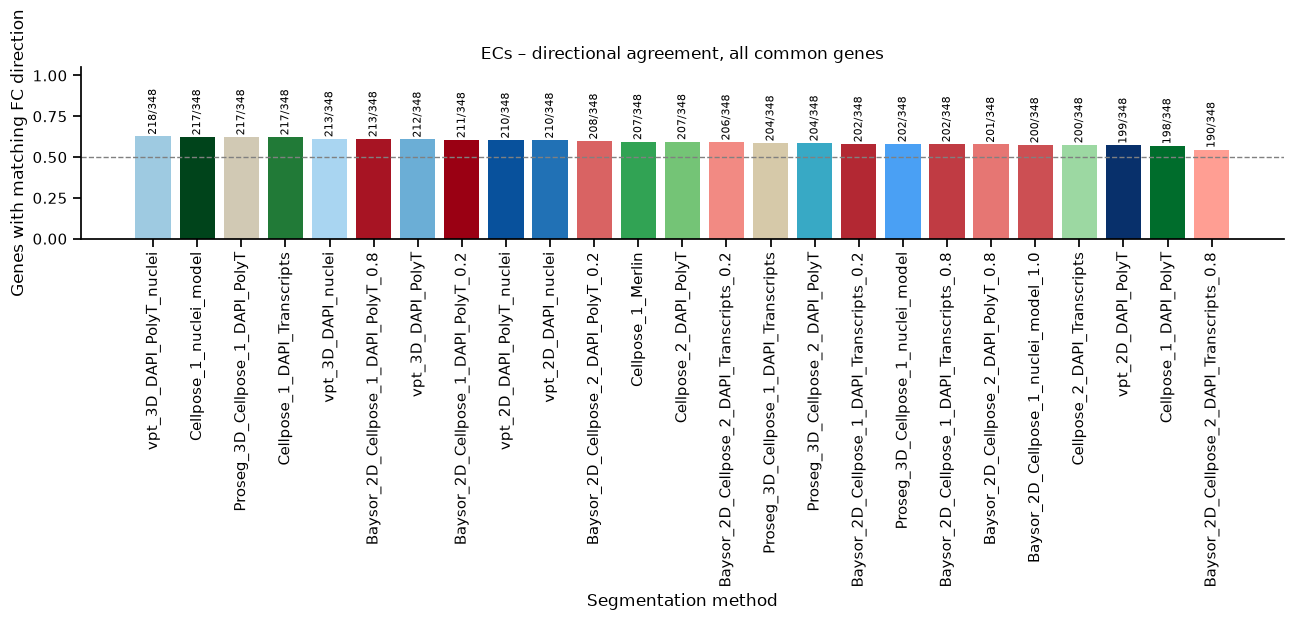

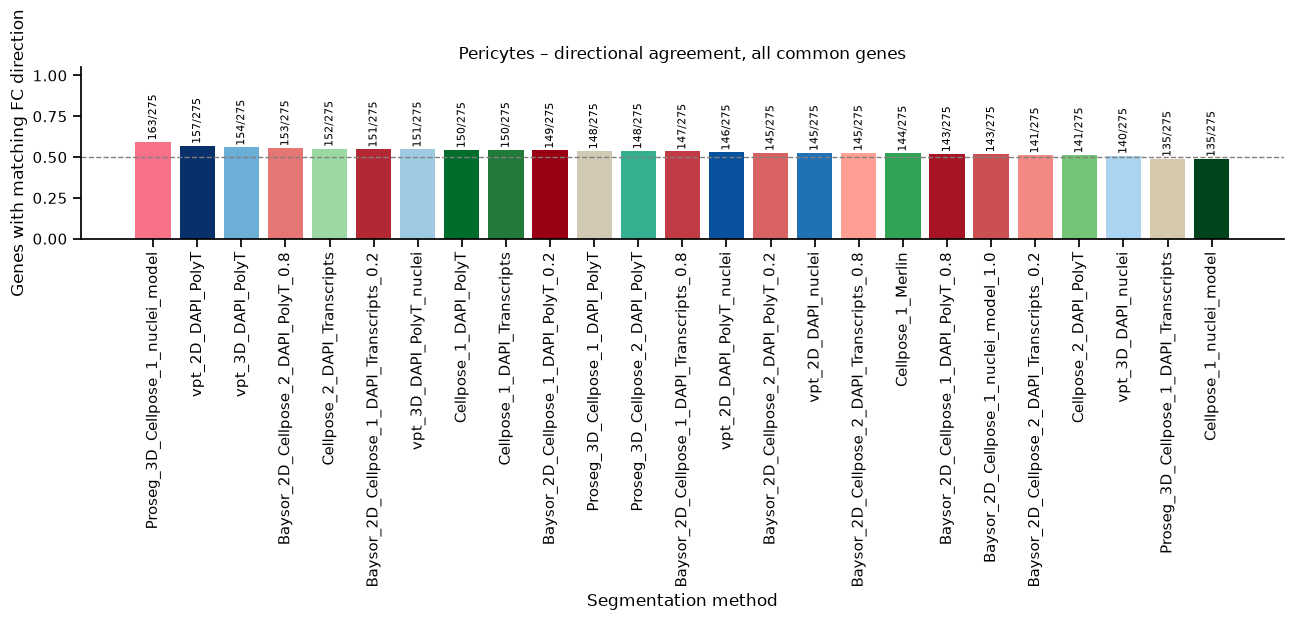

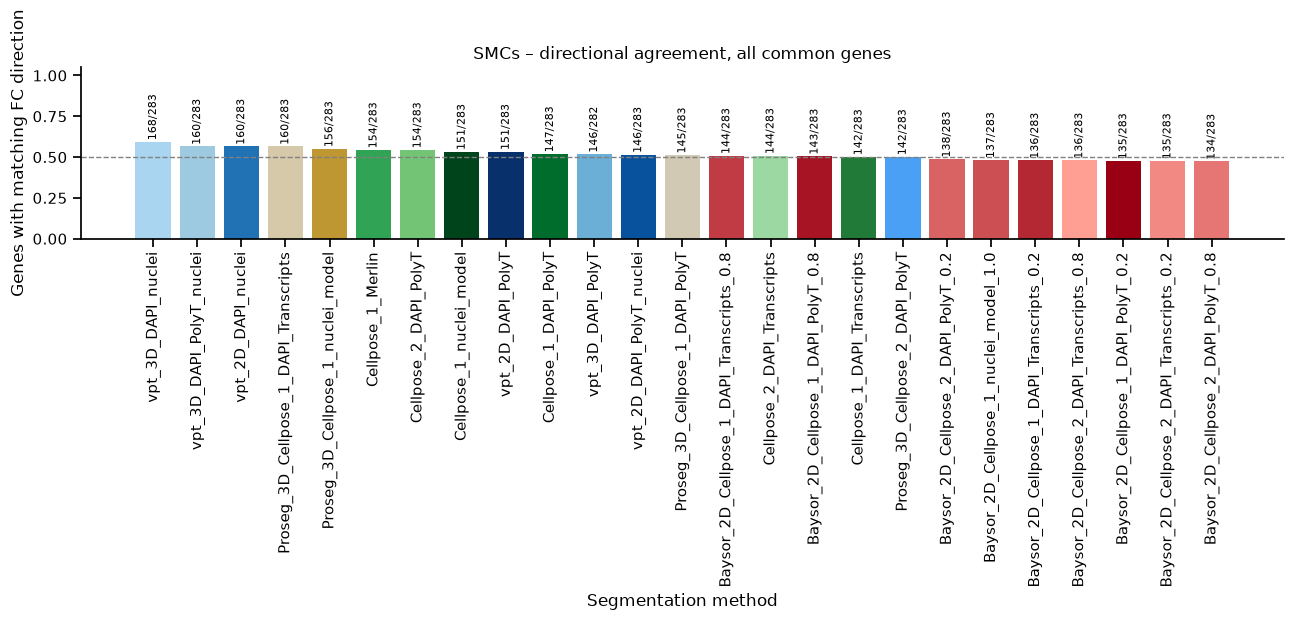

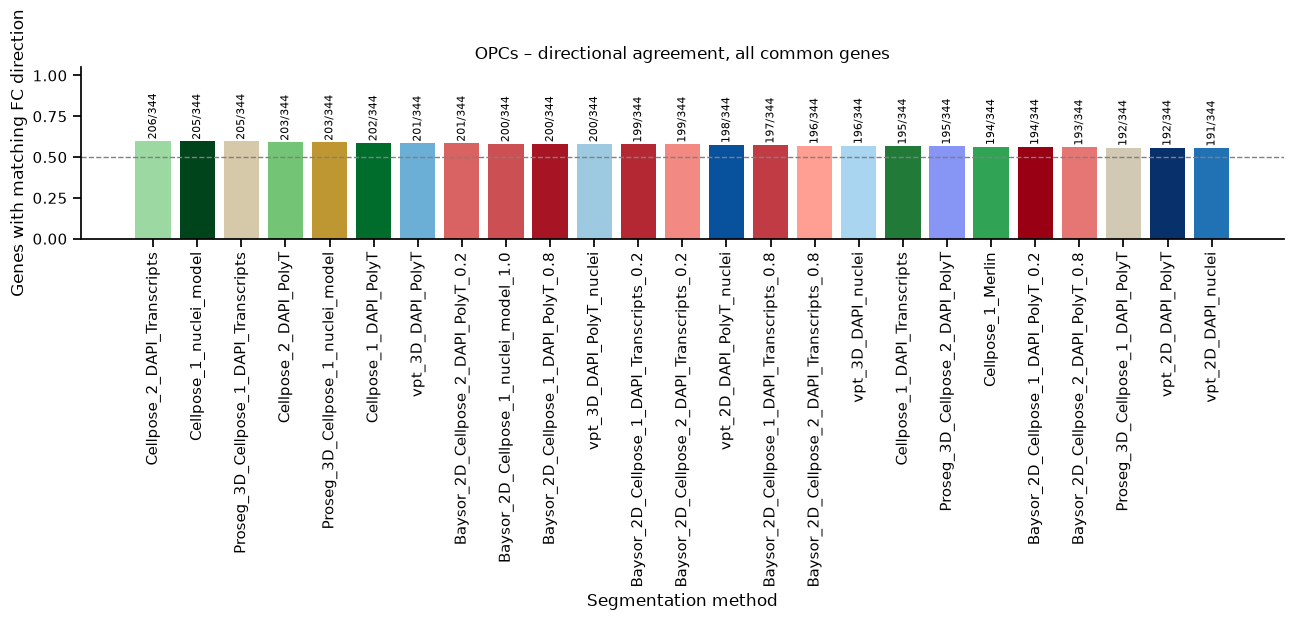

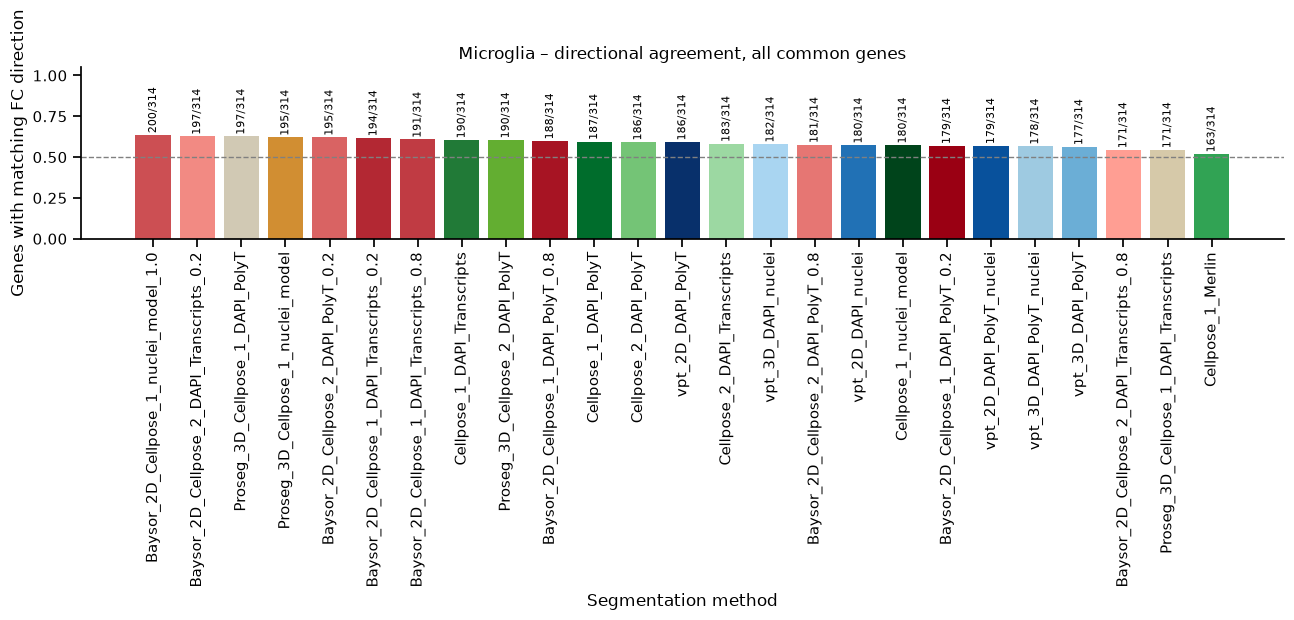

In [16]:
def plot_directional_agreement(res, cell_type, title=None, figsize=(13, 6)):
    """Separate plot of fraction of genes with matching logFC direction."""
    plot_df = res.copy()
    plot_df["fraction_matching_genes"] = np.where(
        plot_df["n_genes"] > 0,
        plot_df["n_matching_genes"] / plot_df["n_genes"],
        np.nan,
    )
    plot_df = plot_df.dropna(subset=["fraction_matching_genes"]).sort_values(
        "fraction_matching_genes", ascending=False
    )
    if plot_df.empty:
        print(f"No directional-agreement results available for {cell_type}.")
        return
    colors = [get_method_palette(plot_df["method"].tolist())[m] for m in plot_df["method"]]
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(plot_df["method"], plot_df["fraction_matching_genes"], color=colors)
    ax.axhline(0.5, linestyle="--", linewidth=1, color="grey")
    for bar, n_match, n_total in zip(bars, plot_df["n_matching_genes"], plot_df["n_genes"]):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01,
            f"{int(n_match)}/{int(n_total)}",
            ha="center", va="bottom", rotation=90, fontsize=8,
        )
    ax.set_xlabel("Segmentation method")
    ax.set_ylabel("Genes with matching FC direction")
    ax.set_ylim(0, 1.05)
    ax.set_title(title or cell_type)
    plt.xticks(rotation=90, ha="center")
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

for cell_type in cell_types_to_plot:
    plot_directional_agreement(
        all_raw_results[cell_type], cell_type,
        f"{cell_type} – directional agreement, all common genes"
    )

In [17]:
def plot_correlation_bars(
    res,
    cell_type,
    title=None,
    figsize=(10, 5),
    save_dir=None,
    filename_suffix=None,
    show_individual_n=False,
):
    """
    Plot Spearman correlations across segmentation methods.

    - Methods are ordered from highest to lowest correlation.
    - Short display names are used for plotting.

    If show_individual_n=False:
        - n_genes is summarized once below the title.
        - If n differs across methods, the range is shown
          (e.g. n = 282–283 genes).

    If show_individual_n=True:
        - n_genes is shown for every individual bar.
        - For positive bars, n is shown above the bar.
        - For negative bars, n is shown immediately below the
          x-axis (y=0), inside the top of the negative bar.

    If save_dir is provided:
        - figures are saved as PNG and PDF.
    """

    # --------------------------------------------------------------
    # Prepare data
    # --------------------------------------------------------------

    plot_df = (
        res
        .dropna(subset=["correlation"])
        .sort_values("correlation", ascending=False)
        .copy()
    )

    if plot_df.empty:
        print(f"No correlations available for {cell_type}.")
        return

    # --------------------------------------------------------------
    # Colours
    # --------------------------------------------------------------

    palette = get_method_palette(
        plot_df["method"].tolist()
    )

    colors = [
        palette[m]
        for m in plot_df["method"]
    ]

    # --------------------------------------------------------------
    # Short method names
    # --------------------------------------------------------------

    plot_df["method_display"] = (
        plot_df["method"]
        .map(display_method)
    )

    # --------------------------------------------------------------
    # Plot
    # --------------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=figsize
    )

    bars = ax.bar(
        plot_df["method_display"],
        plot_df["correlation"],
        color=colors,
    )

    # --------------------------------------------------------------
    # Zero line
    # --------------------------------------------------------------

    ax.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    # --------------------------------------------------------------
    # Title
    # --------------------------------------------------------------

    main_title = title or cell_type

    if show_individual_n:

        # For significant-gene plots, n is shown
        # individually on each bar.
        ax.set_title(
            main_title,
            fontsize=13,
        )

    else:

        # For all-common-gene plots, summarize n once
        # below the title.

        n_values = (
            plot_df["n_genes"]
            .dropna()
            .astype(int)
        )

        if len(n_values) > 0:

            n_min = n_values.min()
            n_max = n_values.max()

            if n_min == n_max:
                n_text = f"n = {n_min} genes"
            else:
                n_text = f"n = {n_min}–{n_max} genes"

            ax.set_title(
                f"{main_title}\n{n_text}",
                fontsize=13,
            )

        else:

            ax.set_title(
                main_title,
                fontsize=13,
            )

    # --------------------------------------------------------------
    # Individual n_genes labels
    # --------------------------------------------------------------

    if show_individual_n:

        # Correlation range is used to calculate a proportional
        # label offset.
        y_min = plot_df["correlation"].min()
        y_max = plot_df["correlation"].max()

        y_range = y_max - y_min

        if y_range == 0:
            y_range = 1

        offset = 0.025 * y_range

        for bar, n in zip(
            bars,
            plot_df["n_genes"],
        ):

            if pd.isna(n):
                continue

            height = bar.get_height()

            # ------------------------------------------------------
            # Positive correlation
            # n is placed above the top of the bar
            # ------------------------------------------------------

            if height >= 0:

                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    height + offset,
                    f"n={int(n)}",
                    ha="center",
                    va="bottom",
                    rotation=90,
                    fontsize=7,
                )

            # ------------------------------------------------------
            # Negative correlation
            # n is placed immediately below y=0
            # ------------------------------------------------------

            else:
            
            
                # Negative bar:
                # place n slightly ABOVE the x-axis for readability
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    offset,
                    f"n={int(n)}",
                    ha="center",
                    va="bottom",
                    rotation=90,
                    fontsize=7,
                    clip_on=False,
                )

    # --------------------------------------------------------------
    # Axis formatting
    # --------------------------------------------------------------

    ax.set_ylabel(
        "Spearman correlation"
    )

    # No redundant x-axis title
    ax.set_xlabel("")

    ax.tick_params(
        axis="x",
        labelrotation=90,
        labelsize=8,
    )

    sns.despine(
        ax=ax
    )

    # --------------------------------------------------------------
    # Layout
    # --------------------------------------------------------------

    plt.tight_layout()

    # --------------------------------------------------------------
    # Save
    # --------------------------------------------------------------

    if save_dir is not None:

        save_dir = Path(save_dir)

        save_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        safe_cell_type = (
            str(cell_type)
            .replace(" ", "_")
            .replace("/", "_")
        )

        suffix = (
            filename_suffix
            if filename_suffix is not None
            else "correlations"
        )

        filename = (
            f"A_{safe_cell_type}_{suffix}"
        )

        # PNG
        png_path = (
            save_dir
            / f"{filename}.png"
        )

        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight",
        )

        # PDF
        pdf_path = (
            save_dir
            / f"{filename}.pdf"
        )

        fig.savefig(
            pdf_path,
            bbox_inches="tight",
        )

        print(f"Saved: {png_path}")
        print(f"Saved: {pdf_path}")

    # --------------------------------------------------------------
    # Show
    # --------------------------------------------------------------

    plt.show()

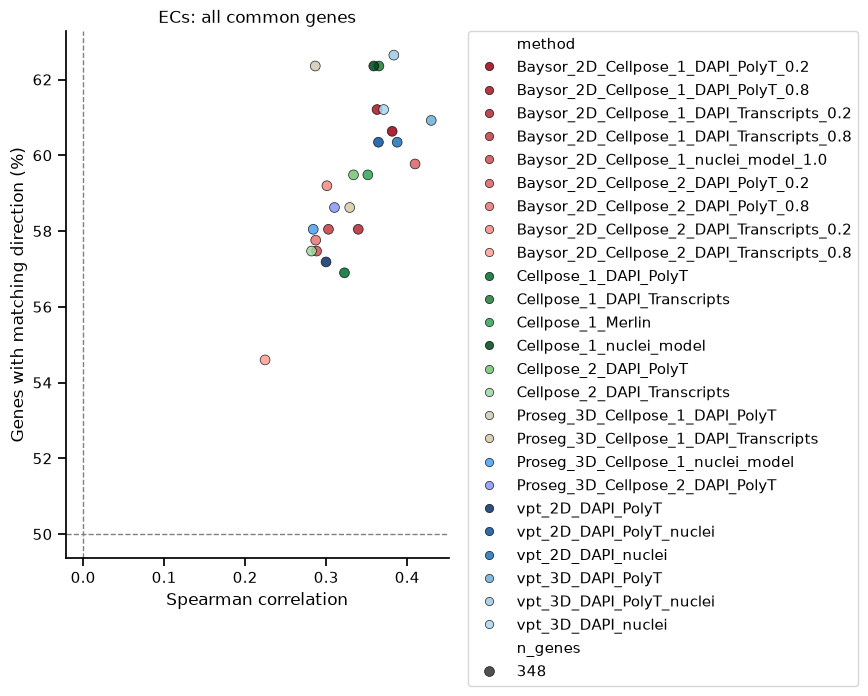

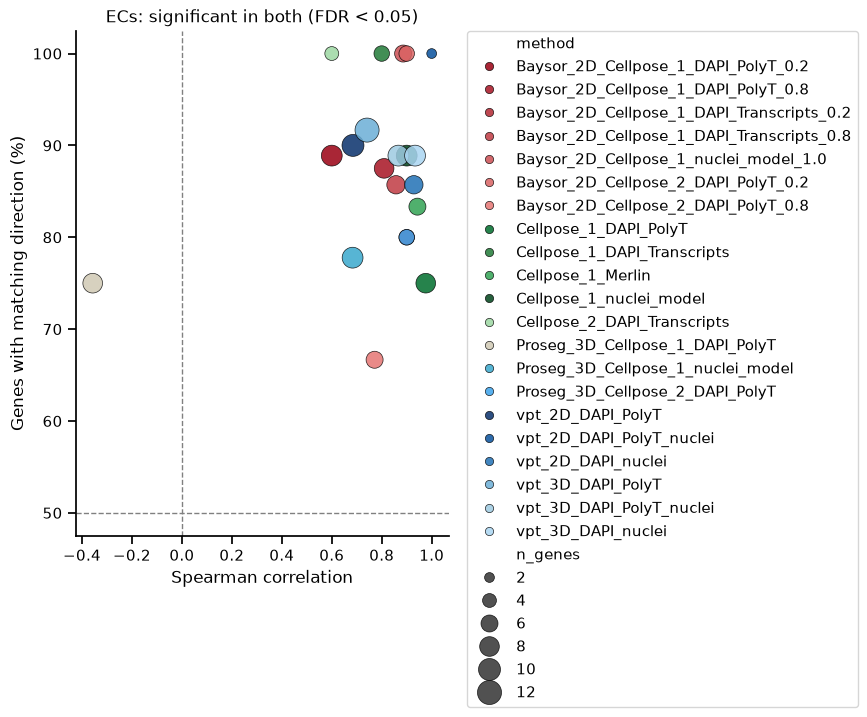

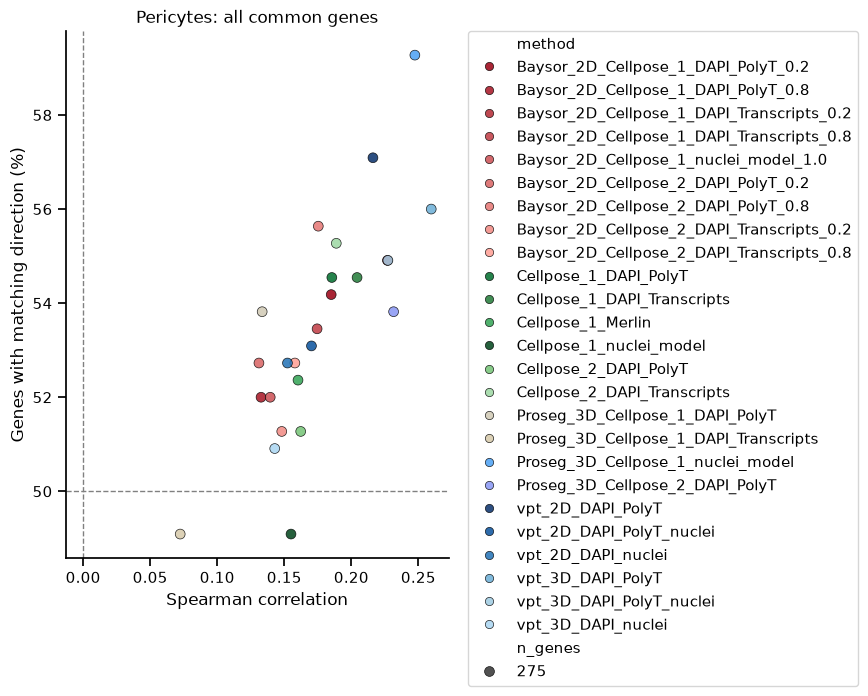

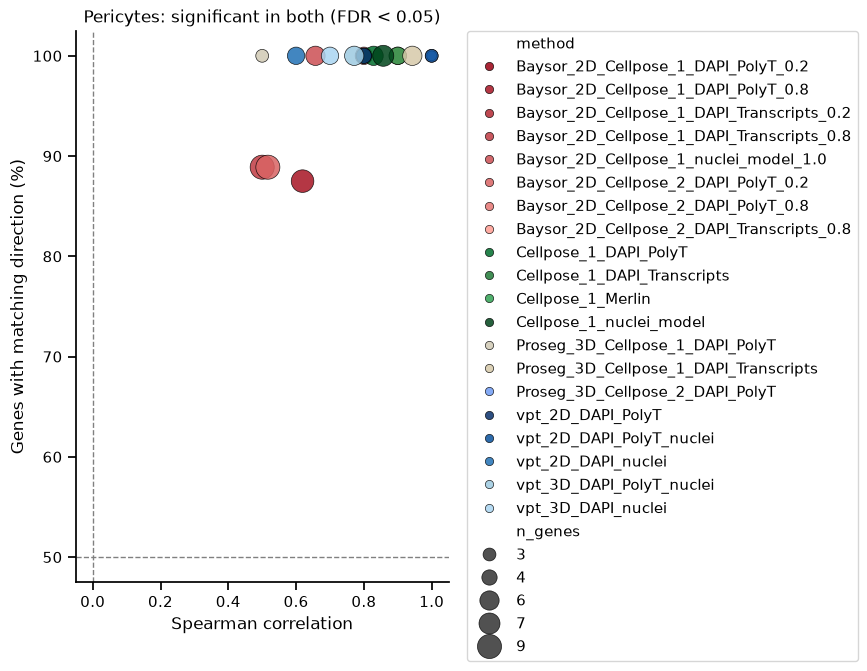

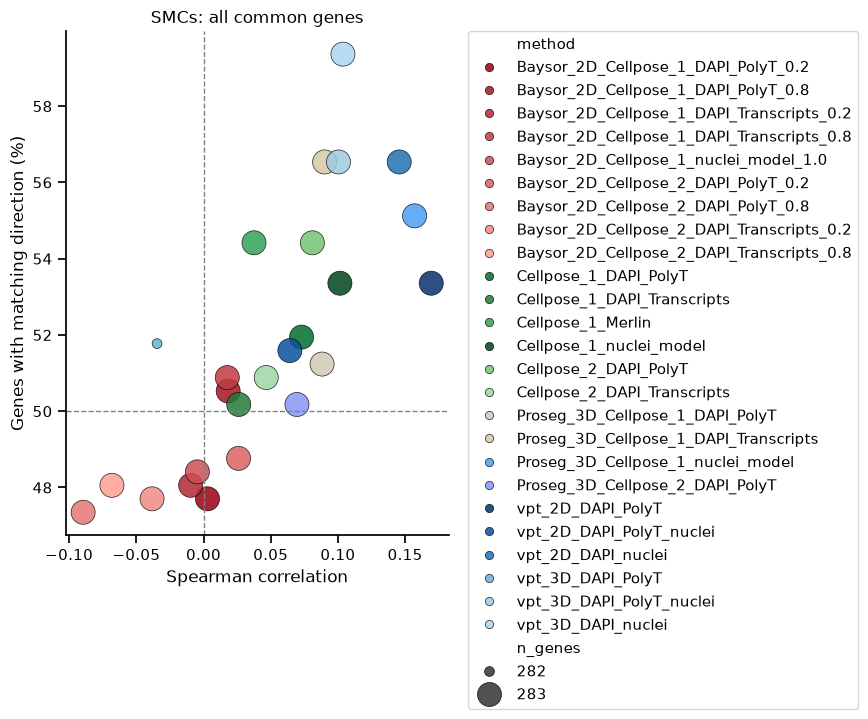

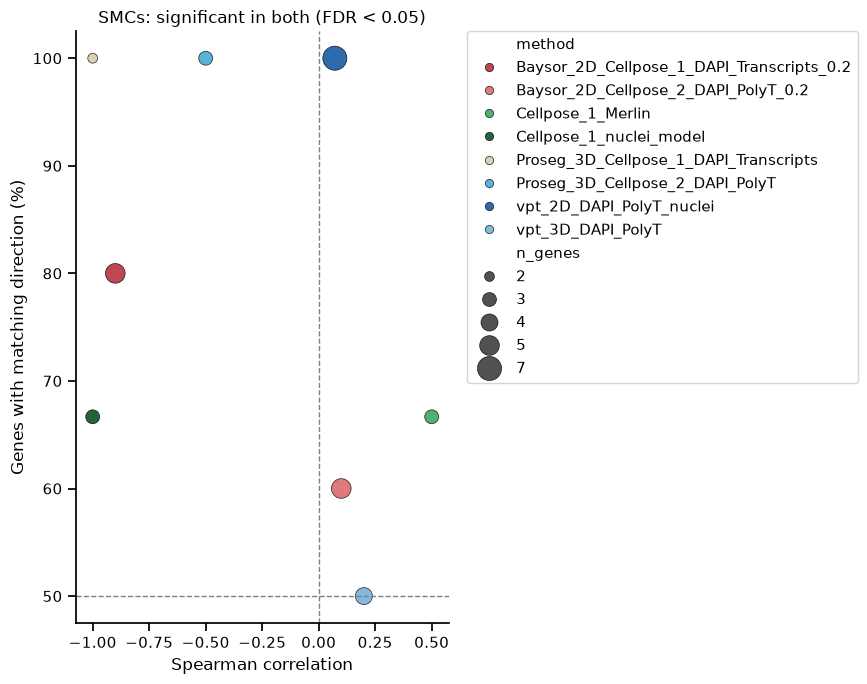

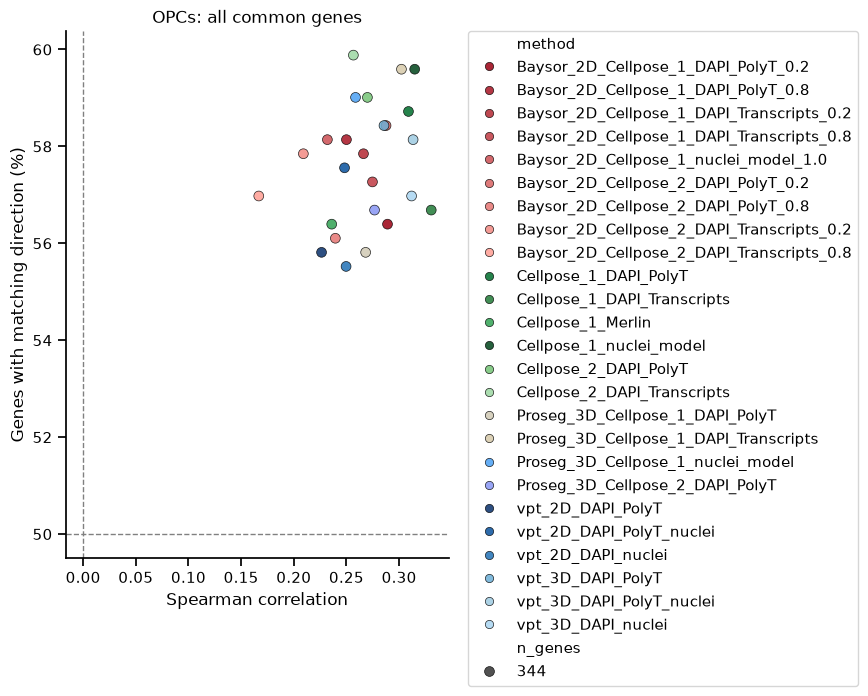

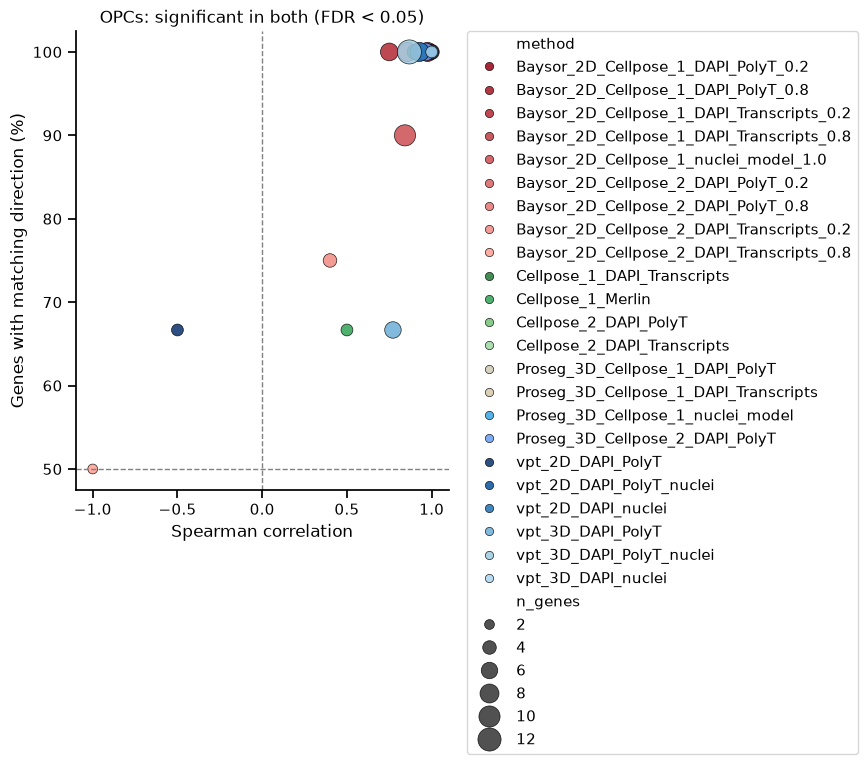

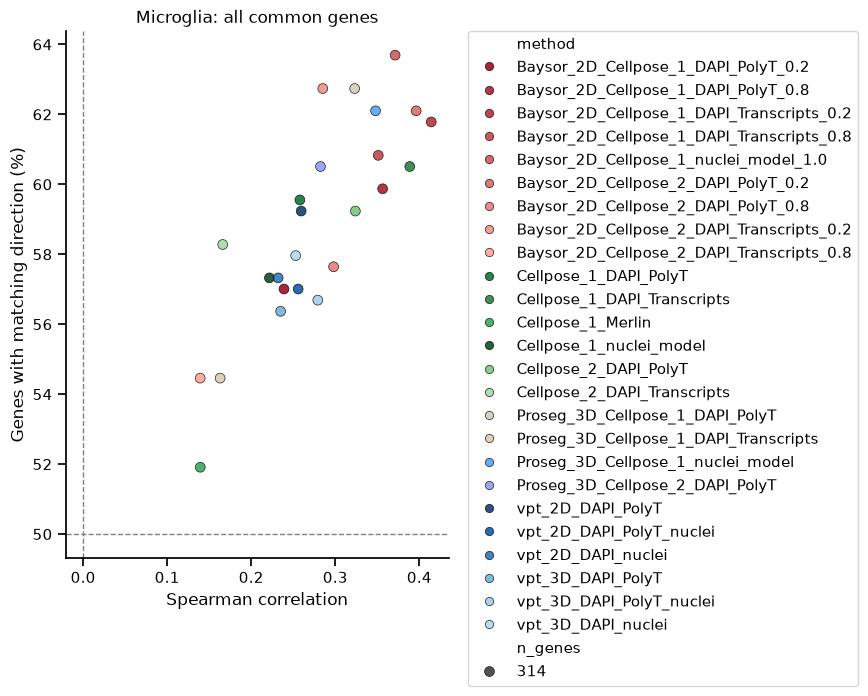

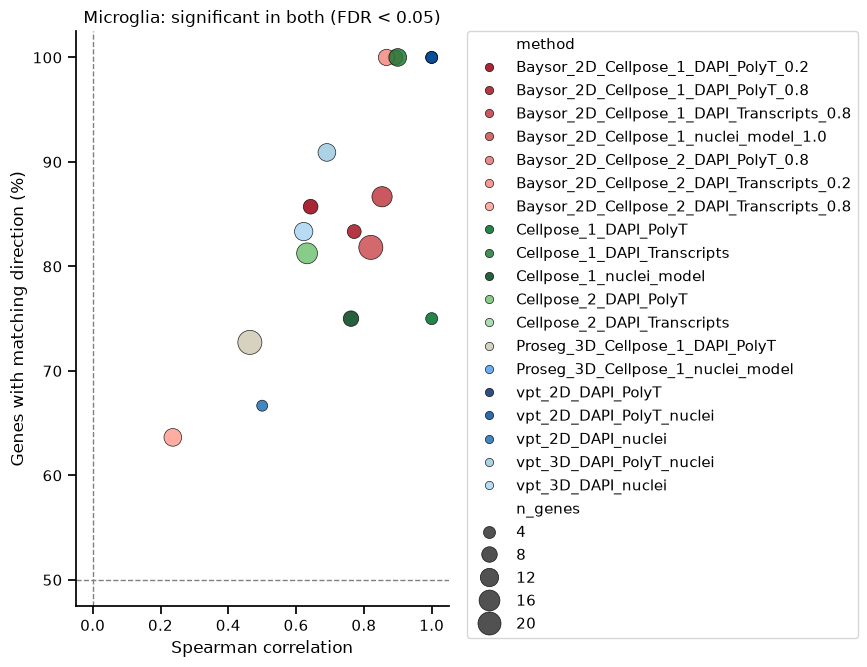

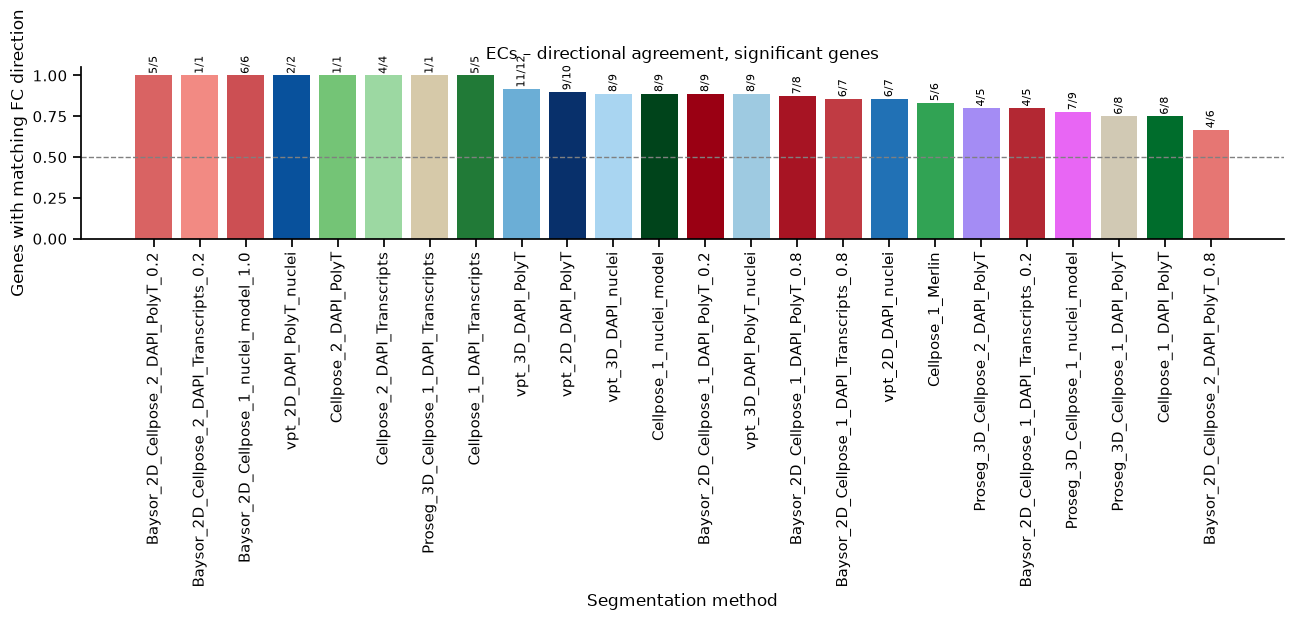

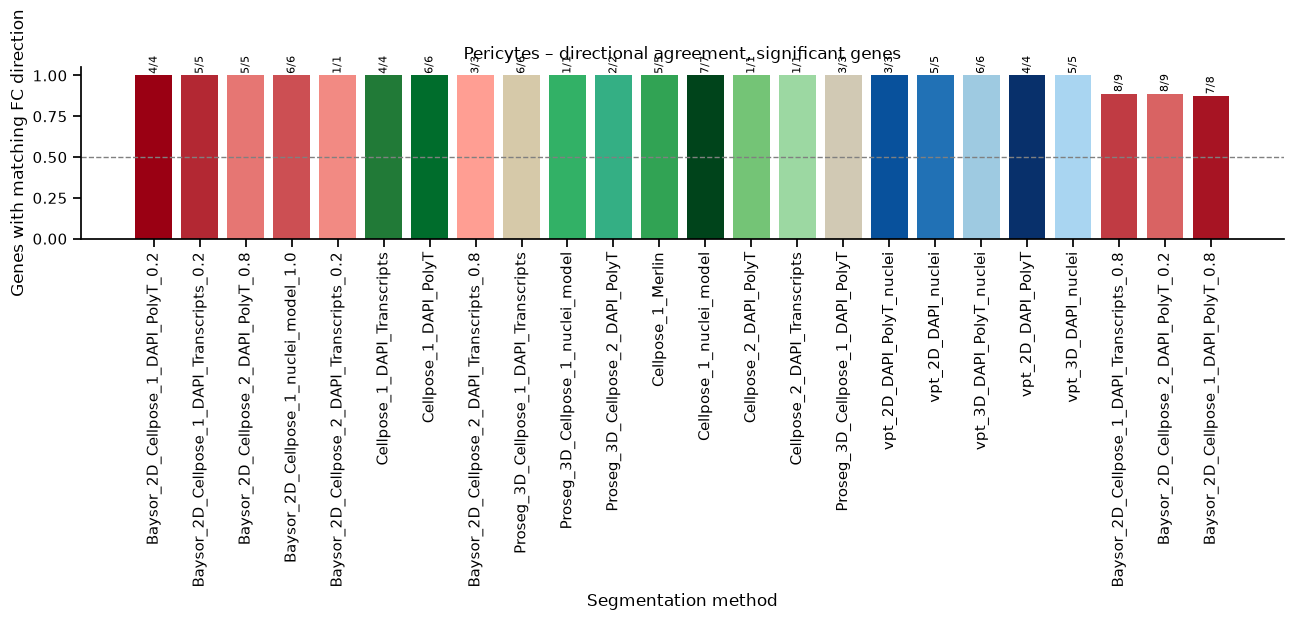

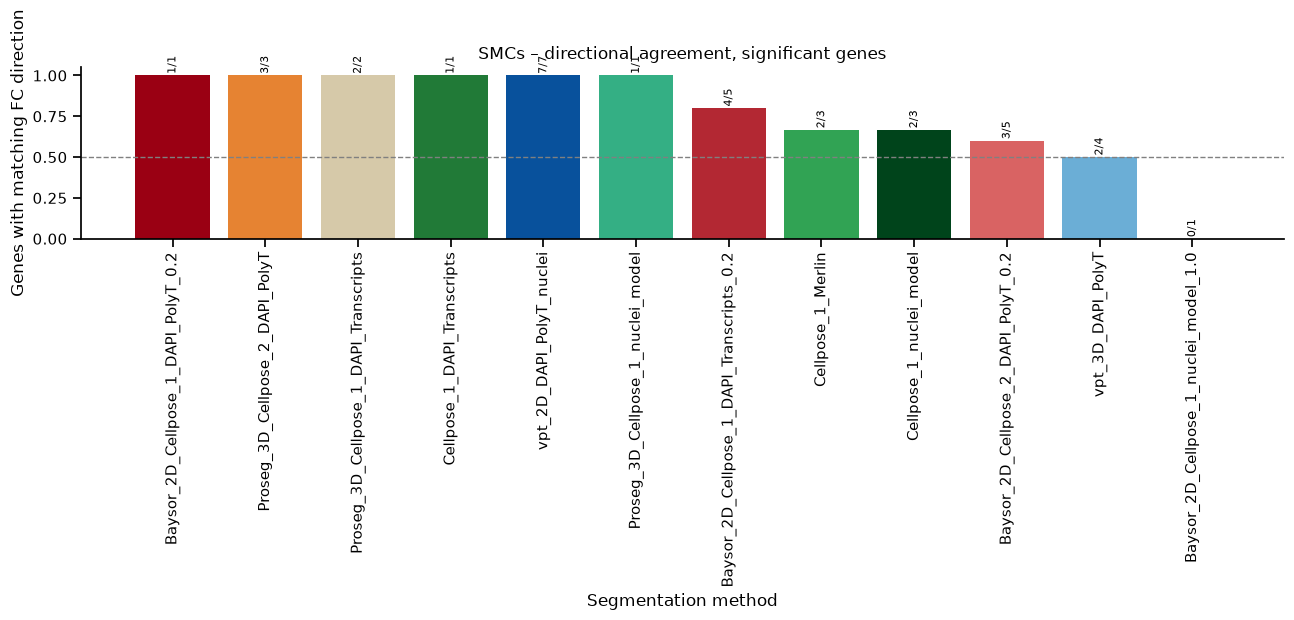

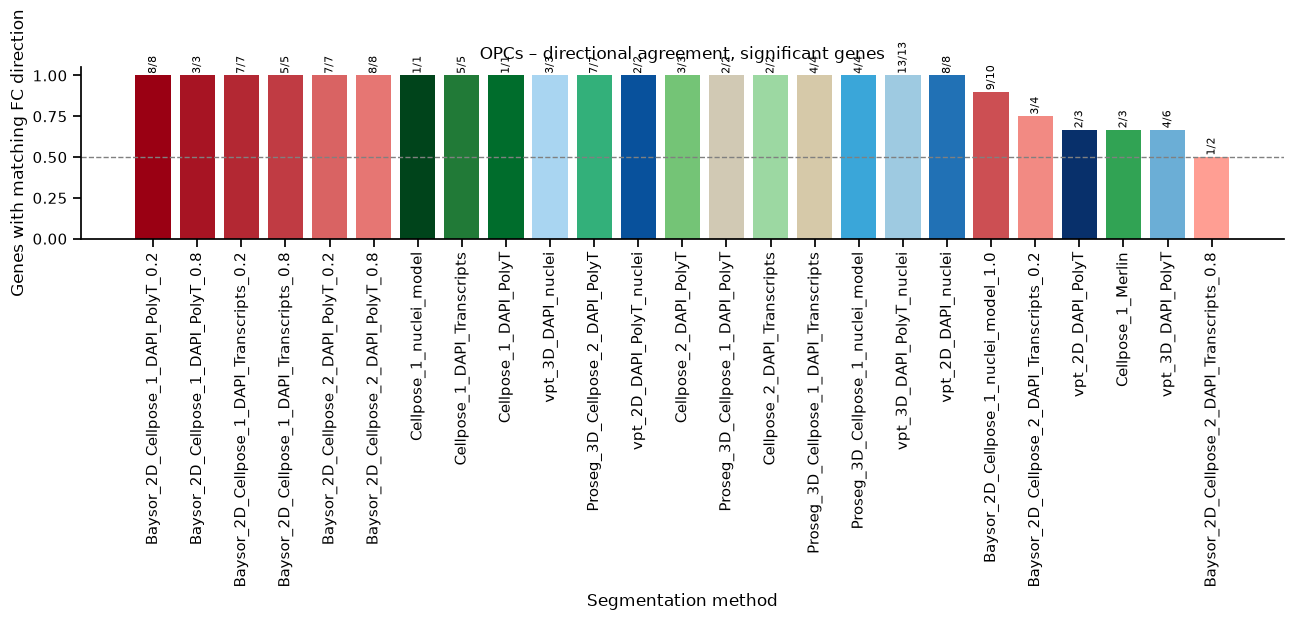

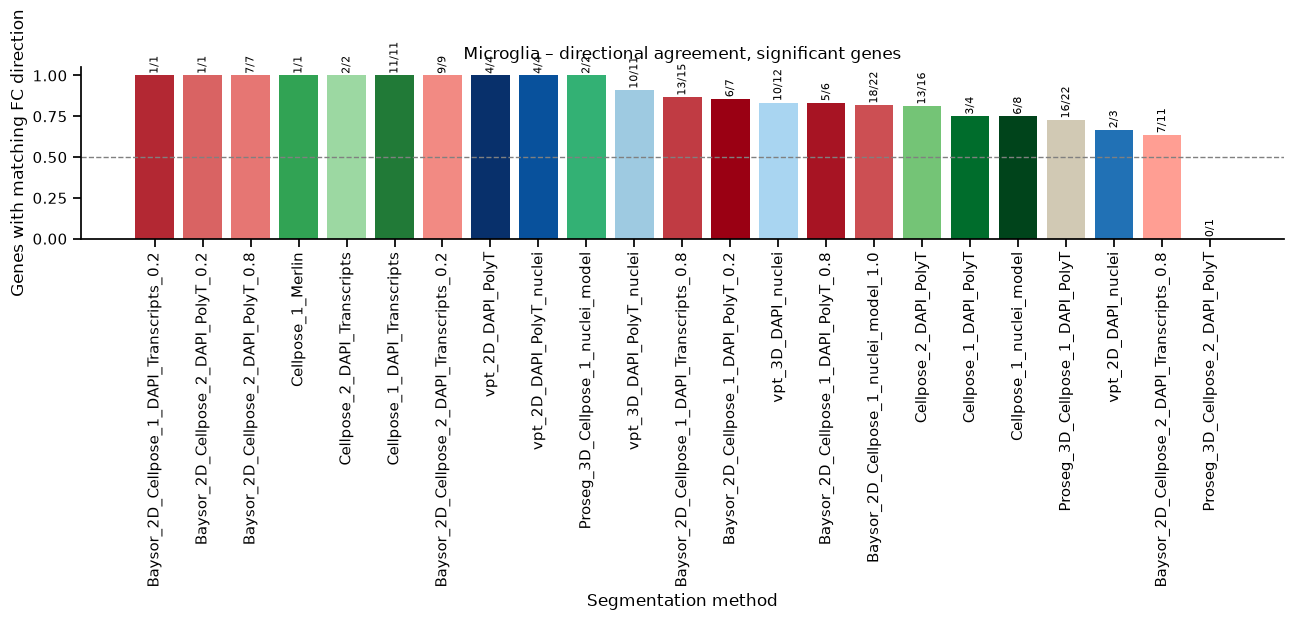

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_ECs_all_genes.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_ECs_all_genes.pdf


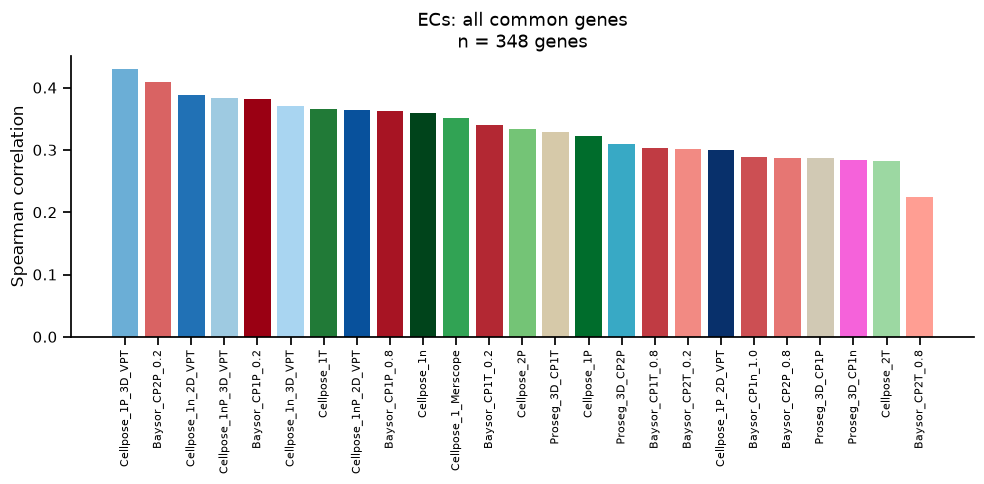

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_ECs_FDR_significant.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_ECs_FDR_significant.pdf


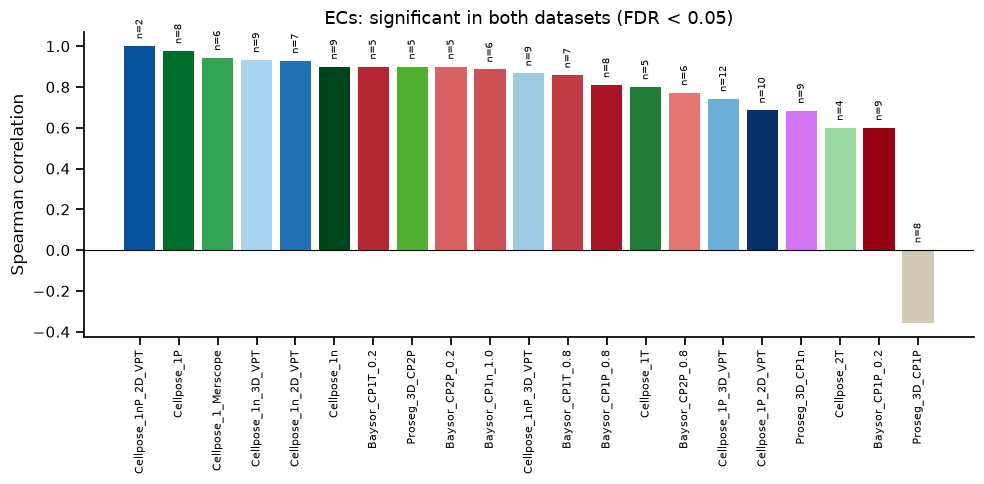

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_Pericytes_all_genes.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_Pericytes_all_genes.pdf


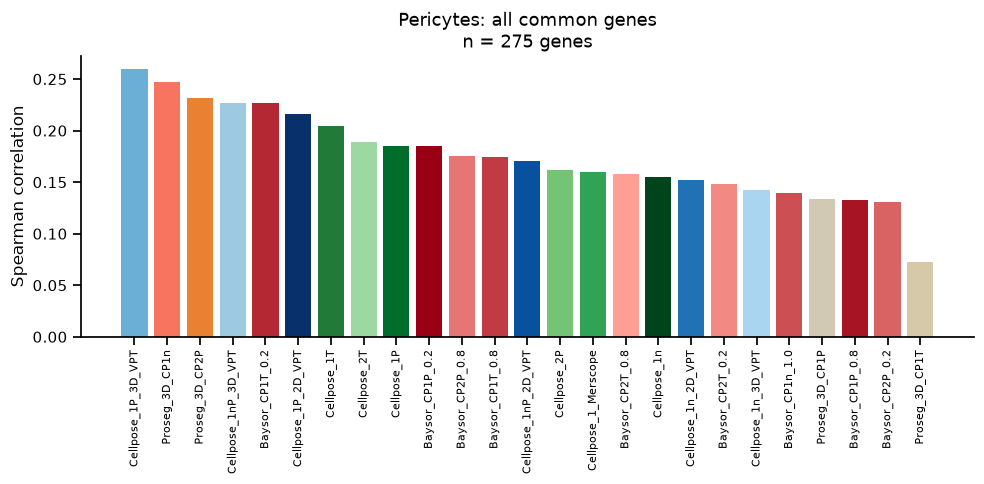

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_Pericytes_FDR_significant.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_Pericytes_FDR_significant.pdf


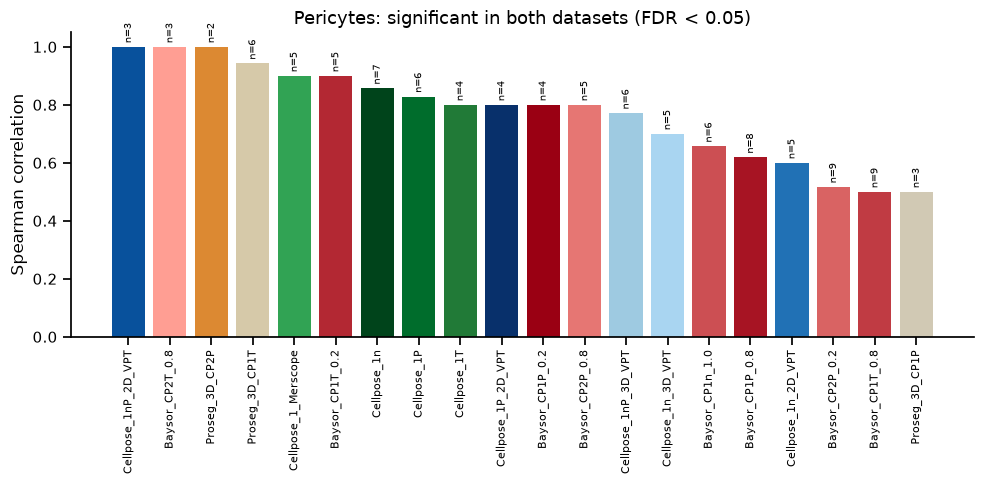

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_SMCs_all_genes.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_SMCs_all_genes.pdf


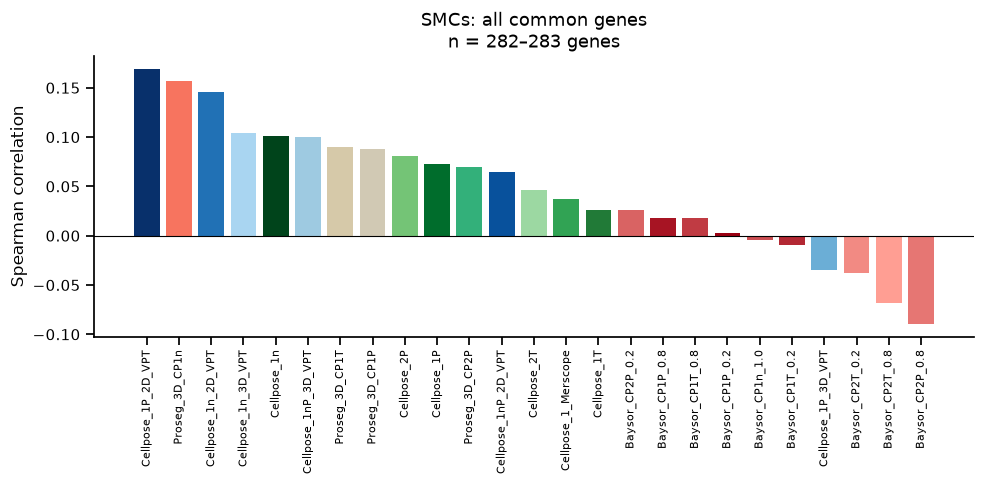

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_SMCs_FDR_significant.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_SMCs_FDR_significant.pdf


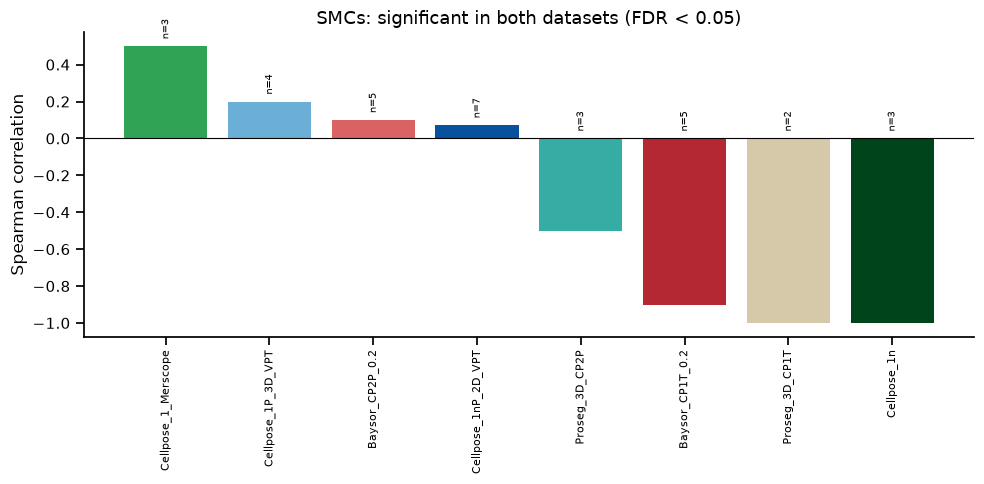

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_OPCs_all_genes.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_OPCs_all_genes.pdf


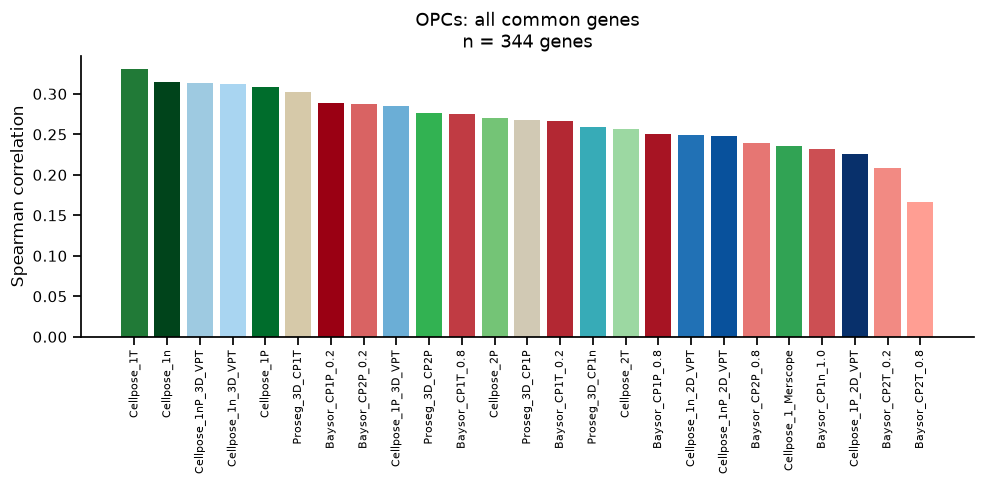

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_OPCs_FDR_significant.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_OPCs_FDR_significant.pdf


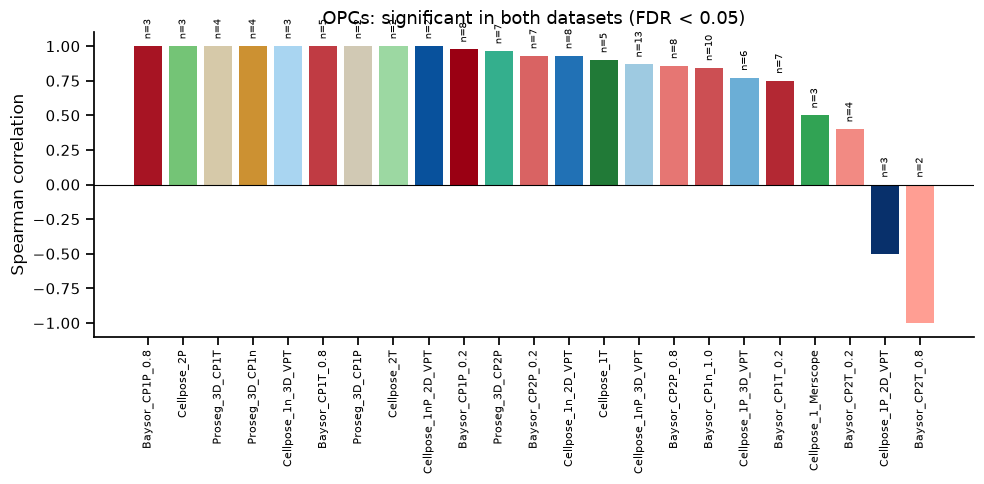

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_Microglia_all_genes.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_Microglia_all_genes.pdf


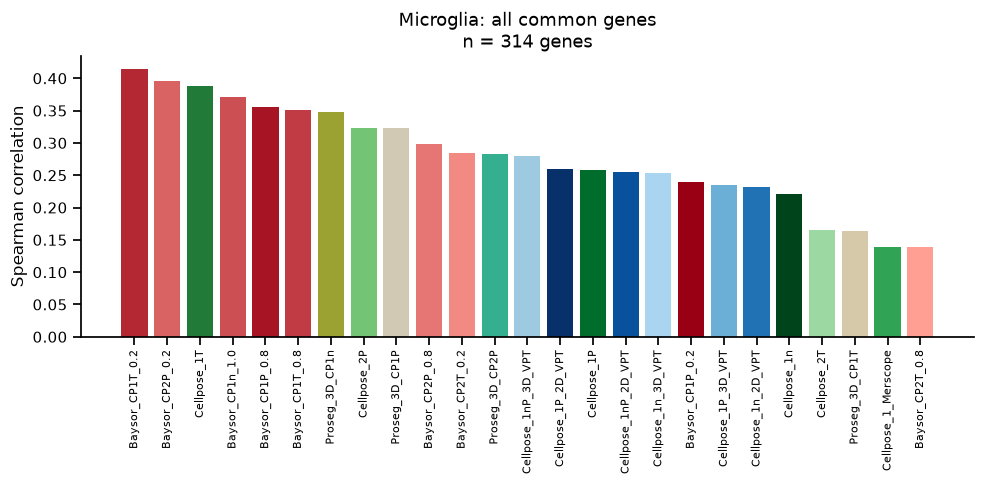

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_Microglia_FDR_significant.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/A_Microglia_FDR_significant.pdf


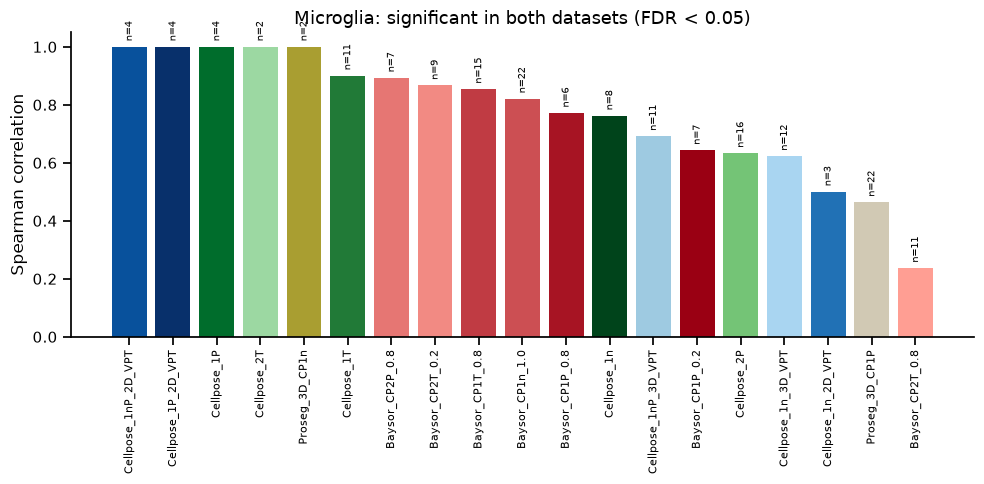

In [18]:
for cell_type in cell_types_to_plot:
    for results, label in [(all_raw_results, "all common genes"), (all_sig_results, f"significant in both (FDR < {alpha})")]:
        plot_method_correlations(results[cell_type], cell_type, f"{cell_type}: {label}")
for cell_type in cell_types_to_plot:
    plot_directional_agreement(
        all_sig_results[cell_type], cell_type,
        f"{cell_type} – directional agreement, significant genes"
    )


for cell_type in cell_types_to_plot:

    # --------------------------------------------------------------
    # All common genes
    # n shown once in subtitle
    # --------------------------------------------------------------

    plot_correlation_bars(
        all_raw_results[cell_type],
        cell_type,
        title=f"{cell_type}: all common genes",
        save_dir=figure_dir,
        filename_suffix="all_genes",
        show_individual_n=False,
    )

    # --------------------------------------------------------------
    # Significant in both datasets
    # individual n shown above each bar
    # --------------------------------------------------------------

    plot_correlation_bars(
        all_sig_results[cell_type],
        cell_type,
        title=f"{cell_type}: significant in both datasets (FDR < {alpha})",
        save_dir=figure_dir,
        filename_suffix="FDR_significant",
        show_individual_n=True,
    )

## 6. Independent best/worst method selection

Rank by Spearman rho separately for each cell type and gene subset, retaining the original minimum of three genes. Small gene sets can yield extreme correlations; method-specific intersections can also affect comparability. Ties retain the original ranking behaviour.

In [19]:
def select_best_worst_methods(results, min_genes=3):
    """
    Select best and worst methods based on Spearman correlation,
    considering only methods with at least `min_genes` genes.

    Best  = highest Spearman correlation
    Worst = lowest Spearman correlation
    """
    ranked = (
        results
        .dropna(subset=["correlation", "n_genes"])
        .loc[lambda x: x["n_genes"] >= min_genes]
        .sort_values("correlation", ascending=False)
    )

    if ranked.empty:
        return None, None

    return ranked.iloc[0]["method"], ranked.iloc[-1]["method"]

In [20]:
ranking_rows = []
for cell_type in cell_types_to_plot:
    for analysis, results in [("all_common_genes", all_raw_results), ("significant_in_both", all_sig_results)]:
        best, worst = select_best_worst_methods(results[cell_type], MIN_GENES_FOR_RANKING)
        ranking_rows.append(dict(cell_type=cell_type, analysis=analysis, best=best, worst=worst))
rankings = pd.DataFrame(ranking_rows)
rankings.to_csv(out_path / "best_worst_method_rankings.csv", index=False)
display(rankings)

,cell_type,analysis,best,worst
0,ECs,all_common_genes,vpt_3D_DAPI_PolyT,Baysor_2D_Cellpose_2_DAPI_Transcripts_0.8
1,ECs,significant_in_both,Cellpose_1_DAPI_PolyT,Proseg_3D_Cellpose_1_DAPI_PolyT
2,Pericytes,all_common_genes,vpt_3D_DAPI_PolyT,Proseg_3D_Cellpose_1_DAPI_Transcripts
3,Pericytes,significant_in_both,Baysor_2D_Cellpose_2_DAPI_Transcripts_0.8,Proseg_3D_Cellpose_1_DAPI_PolyT
4,SMCs,all_common_genes,vpt_2D_DAPI_PolyT,Baysor_2D_Cellpose_2_DAPI_PolyT_0.8
5,SMCs,significant_in_both,Cellpose_1_Merlin,Cellpose_1_nuclei_model
6,OPCs,all_common_genes,Cellpose_1_DAPI_Transcripts,Baysor_2D_Cellpose_2_DAPI_Transcripts_0.8
7,OPCs,significant_in_both,Baysor_2D_Cellpose_1_DAPI_PolyT_0.8,vpt_2D_DAPI_PolyT
8,Microglia,all_common_genes,Baysor_2D_Cellpose_1_DAPI_Transcripts_0.2,Baysor_2D_Cellpose_2_DAPI_Transcripts_0.8
9,Microglia,significant_in_both,Cellpose_1_DAPI_PolyT,Baysor_2D_Cellpose_2_DAPI_Transcripts_0.8


## 7. Gene-level comparison with Jin

Each row uses its independently ranked best and worst methods. Marker genes are annotated in the significant-gene panels.

In [21]:
def plot_gene_level_best_worst(
    cell_type,
    raw_res,
    sig_res,
    marker_genes,
    method_colors,
    method_display_names,
    alpha=0.05,
    min_genes=3,
    figsize=(12, 10),
    save_dir=None,
):
    """
    Compare single-cell and spatial logFC for best/worst segmentation
    methods.

    Row 1:
        Best/worst methods selected using all common genes.

    Row 2:
        Best/worst methods selected using genes significant in both
        datasets (FDR < alpha).

    Original method names are used internally for calculations and colours.
    Short method names from method_display_names are used for plot titles.

    Marker genes are labelled in significant-gene panels.

    Statistics are displayed above each plotting area to avoid overlap
    with data points.
    """

    # --------------------------------------------------------------
    # Helper for short method names
    # --------------------------------------------------------------

    def display_method(method):
        return method_display_names.get(method, method)

    # --------------------------------------------------------------
    # Select best/worst methods
    # --------------------------------------------------------------

    best_all, worst_all = select_best_worst_methods(
        raw_res,
        min_genes=min_genes,
    )

    best_sig, worst_sig = select_best_worst_methods(
        sig_res,
        min_genes=min_genes,
    )

    markers = set(
        marker_genes.get(cell_type, [])
    )

    # --------------------------------------------------------------
    # Figure
    # --------------------------------------------------------------

    fig, axes = plt.subplots(
        2,
        2,
        figsize=figsize,
    )

    analyses = [
        {
            "label": "All common genes",
            "significant_only": False,
            "best": best_all,
            "worst": worst_all,
        },
        {
            "label": "FDR < 0.05 in both datasets",
            "significant_only": True,
            "best": best_sig,
            "worst": worst_sig,
        },
    ]

    # --------------------------------------------------------------
    # Plot
    # --------------------------------------------------------------

    for row, analysis in enumerate(analyses):

        methods = [
            ("Best", analysis["best"]),
            ("Worst", analysis["worst"]),
        ]

        for col, (rank_label, method) in enumerate(methods):

            ax = axes[row, col]

            # ------------------------------------------------------
            # No valid method
            # ------------------------------------------------------

            if method is None:

                ax.text(
                    0.5,
                    0.5,
                    f"No method with n ≥ {min_genes}",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                )

                ax.set_axis_off()
                continue

            # ------------------------------------------------------
            # Get genes
            # Original method name is used internally
            # ------------------------------------------------------

            paired = get_common_genes(
                method=method,
                cell_type=cell_type,
                significant_only=analysis["significant_only"],
                alpha=alpha,
            )

            n_genes = len(paired)

            if n_genes == 0:

                ax.text(
                    0.5,
                    0.5,
                    "No genes available",
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                )

                ax.set_axis_off()
                continue

            # ------------------------------------------------------
            # Statistics
            # ------------------------------------------------------

            rho, pvalue = safe_spearman(
                paired["logFC_jin"],
                paired["logFC_spatial"],
            )

            matching = (
                np.sign(paired["logFC_jin"])
                ==
                np.sign(paired["logFC_spatial"])
            )

            fraction_matching = (
                matching.sum() / n_genes
            )

            # ------------------------------------------------------
            # Scatter
            # ------------------------------------------------------

            method_color = method_colors.get(
                method,
                "grey",
            )

            ax.scatter(
                paired["logFC_jin"],
                paired["logFC_spatial"],
                s=35,
                color=method_color,
                alpha=0.75,
                edgecolors="none",
                zorder=2,
            )

            # ------------------------------------------------------
            # Zero lines
            # ------------------------------------------------------

            ax.axhline(
                0,
                color="grey",
                linestyle="--",
                linewidth=0.8,
                alpha=0.7,
                zorder=1,
            )

            ax.axvline(
                0,
                color="grey",
                linestyle="--",
                linewidth=0.8,
                alpha=0.7,
                zorder=1,
            )

            # ------------------------------------------------------
            # Updated method name
            # ------------------------------------------------------

            method_label = display_method(method)

            # ------------------------------------------------------
            # Subplot title
            #
            # Method + analysis type are kept together.
            # pad reserves room for statistics underneath.
            # ------------------------------------------------------

            ax.set_title(
                f"{rank_label} · {method_label}\n"
                f"{analysis['label']}",
                fontsize=11,
                fontweight="bold",
                pad=38,
            )

            # ------------------------------------------------------
            # Statistics
            #
            # Positioned ABOVE the plotting area rather than inside it.
            # ------------------------------------------------------

            ax.text(
                0.5,
                1.035,
                (
                    f"rho = {rho:.2f}   "
                    f"p = {pvalue:.2e}   "
                    f"n = {n_genes}   "
                    f"agreement = {fraction_matching:.0%}"
                ),
                transform=ax.transAxes,
                ha="center",
                va="bottom",
                fontsize=9,
                clip_on=False,
            )

            # ------------------------------------------------------
            # Marker labels for significant panels
            # ------------------------------------------------------
            
            if analysis["significant_only"]:
            
                marker_df = paired[
                    paired["gene"].isin(markers)
                ].copy()
            
                texts = []
            
                # Scale initial vertical offset to the actual y-axis range
                y_range = (
                    paired["logFC_spatial"].max()
                    - paired["logFC_spatial"].min()
                )
            
                if y_range == 0:
                    y_range = 1
            
                initial_offset = 0.06 * y_range
            
                for _, gene_row in marker_df.iterrows():
            
                    texts.append(
                        ax.text(
                            gene_row["logFC_jin"],
                            gene_row["logFC_spatial"] + initial_offset,
                            gene_row["gene"],
                            fontsize=8,
                            fontweight="bold",
                            ha="center",
                            va="bottom",
                            zorder=5,
                        )
                    )
            
                if texts:
            
                    adjust_text(
                        texts,
                        ax=ax,
            
                        # Original point coordinates
                        target_x=marker_df[
                            "logFC_jin"
                        ].to_numpy(),
            
                        target_y=marker_df[
                            "logFC_spatial"
                        ].to_numpy(),
            
                        # Keep labels within plotting area
                        ensure_inside_axes=True,
            
                        # Avoid labels/lines crossing where possible
                        prevent_crossings=True,
            
                        # More separation between labels
                        expand=(1.3, 1.5),
            
                        # Stronger movement away from other labels
                        force_text=(0.5, 0.8),
            
                        # Stronger movement away from points
                        force_static=(0.3, 0.5),
            
                        # Allow labels to move sufficiently
                        max_move=(40, 50),
            
                        # Always draw connector
                        min_arrow_len=0,
            
                        # Poster-visible connector
                        arrowprops=dict(
                            arrowstyle="-",
                            color="black",
                            linewidth=1.2,
                            alpha=0.9,
                        ),
                    )

            # ------------------------------------------------------
            # Axis labels
            # ------------------------------------------------------

            # Only bottom row gets x-axis label
            if row == 1:

                ax.set_xlabel(
                    "Single-cell log₂FC"
                )

            else:

                ax.set_xlabel("")

            # Only left column gets y-axis label
            if col == 0:

                ax.set_ylabel(
                    "Spatial log₂FC"
                )

            else:

                ax.set_ylabel("")

            # ------------------------------------------------------
            # Styling
            # ------------------------------------------------------

            sns.despine(
                ax=ax
            )

    # --------------------------------------------------------------
    # Main figure title
    # --------------------------------------------------------------

    fig.suptitle(
        f"{cell_type} – log₂FC correlation",
        fontsize=15,
        fontweight="bold",
        y=0.98,
    )

    # --------------------------------------------------------------
    # Layout
    #
    # hspace is deliberately larger so that titles/statistics for
    # the lower row do not collide with the upper plots.
    #
    # Do NOT use tight_layout() afterwards, because it can undo
    # this deliberate spacing.
    # --------------------------------------------------------------

    fig.subplots_adjust(
        hspace=0.70,
        wspace=0.25,
        top=0.84,
        bottom=0.09,
        left=0.10,
        right=0.97,
    )

    # --------------------------------------------------------------
    # Save
    # --------------------------------------------------------------

    if save_dir is not None:

        save_dir = Path(save_dir)

        save_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        safe_cell_type = (
            str(cell_type)
            .replace(" ", "_")
            .replace("/", "_")
        )

        filename = (
            f"B_{safe_cell_type}_"
            f"gene_level_concordance"
        )

        # PNG
        png_path = (
            save_dir
            / f"{filename}.png"
        )

        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight",
        )

        # PDF
        pdf_path = (
            save_dir
            / f"{filename}.pdf"
        )

        fig.savefig(
            pdf_path,
            bbox_inches="tight",
        )

        print(f"Saved: {png_path}")
        print(f"Saved: {pdf_path}")

    # --------------------------------------------------------------
    # Show
    # --------------------------------------------------------------

    plt.show()

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/B_ECs_gene_level_concordance.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/B_ECs_gene_level_concordance.pdf


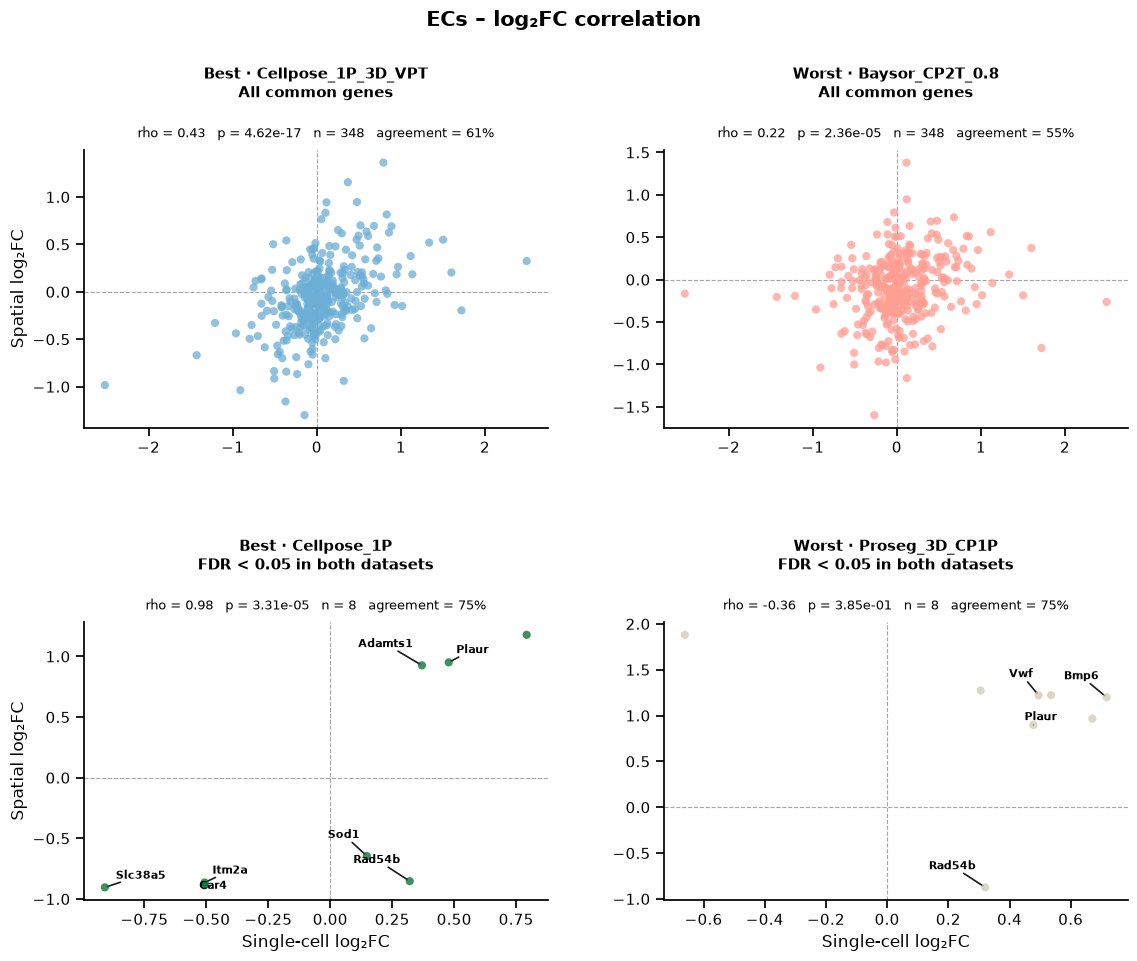

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/B_Pericytes_gene_level_concordance.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/B_Pericytes_gene_level_concordance.pdf


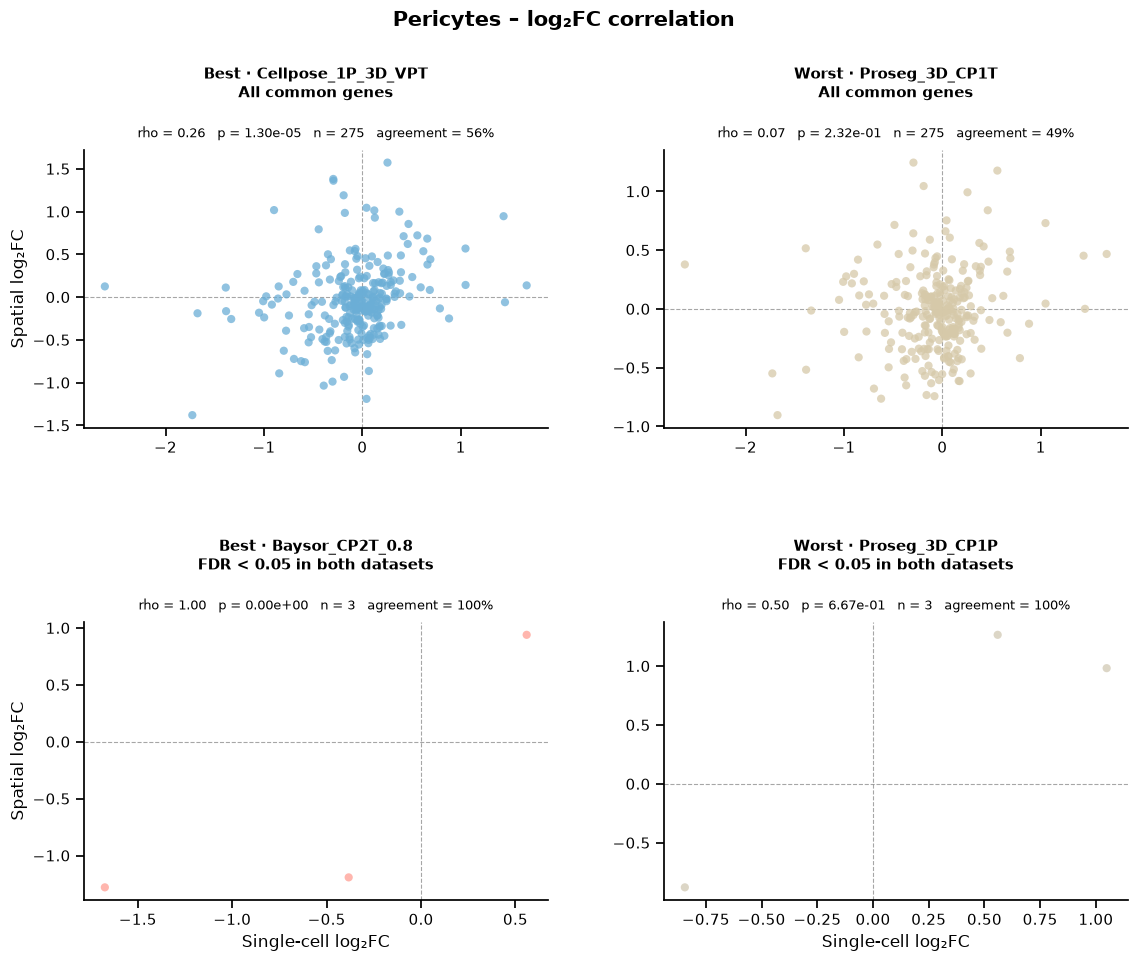

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/B_SMCs_gene_level_concordance.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/B_SMCs_gene_level_concordance.pdf


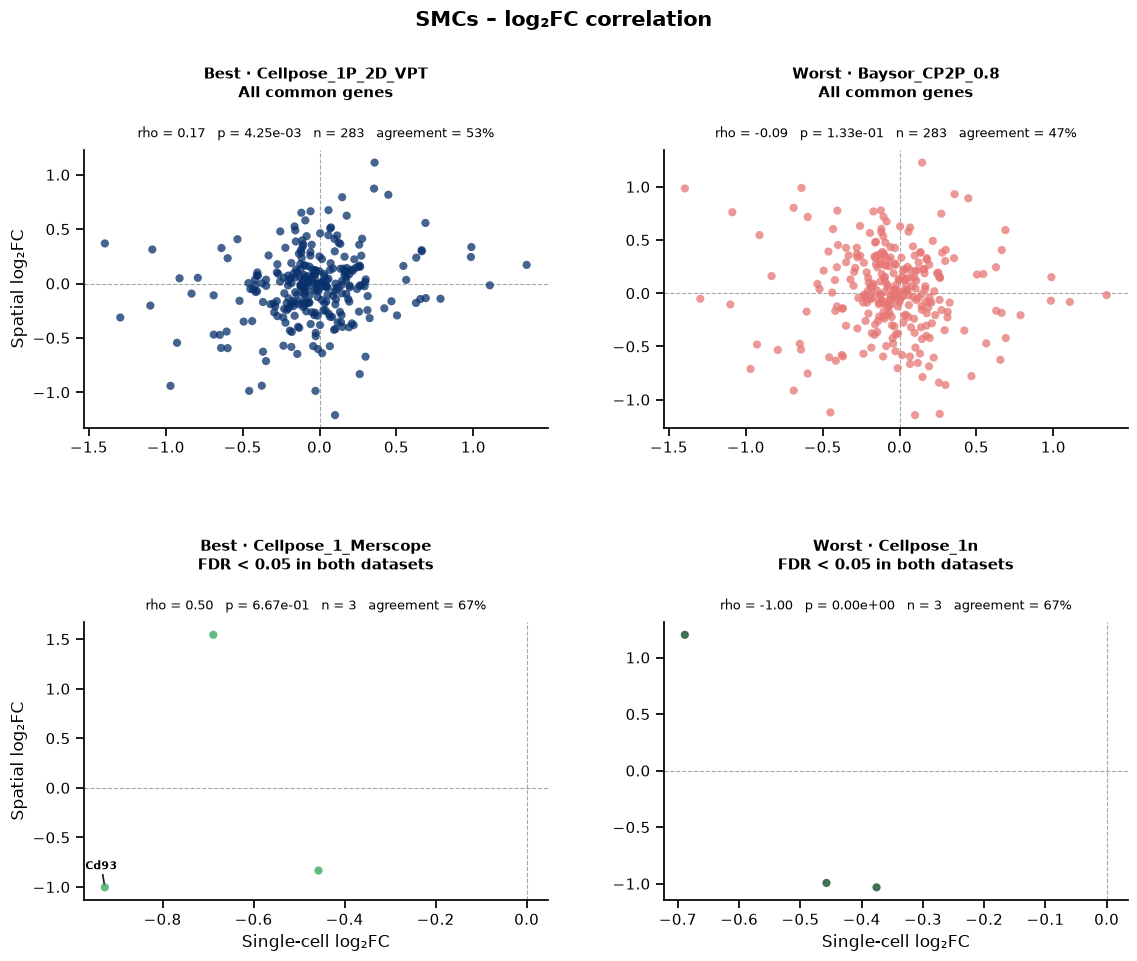

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/B_OPCs_gene_level_concordance.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/B_OPCs_gene_level_concordance.pdf


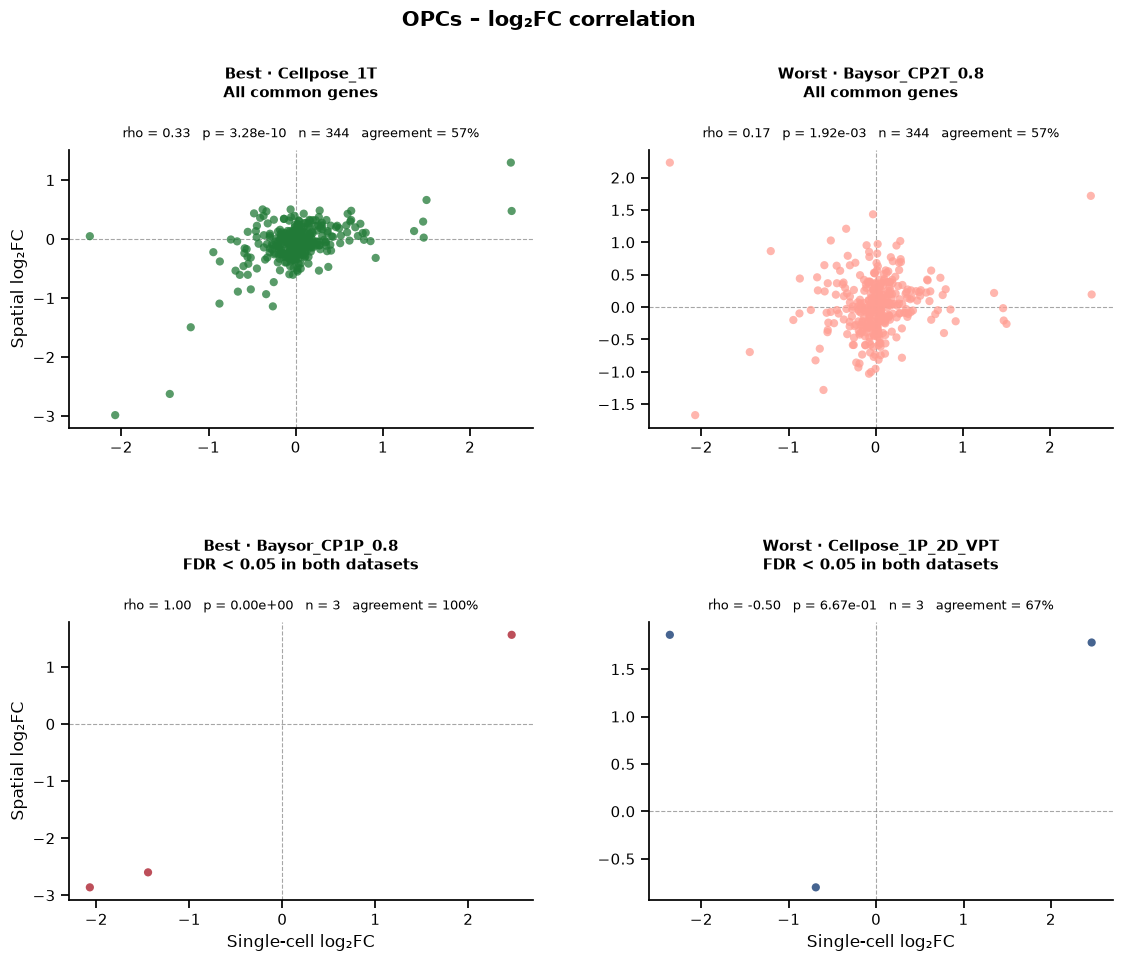

Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/B_Microglia_gene_level_concordance.png
Saved: /dss/dssfs03/pn52re/pn52re-dss-0001/cellseg-benchmark/misc/dea/figures_poster/B_Microglia_gene_level_concordance.pdf


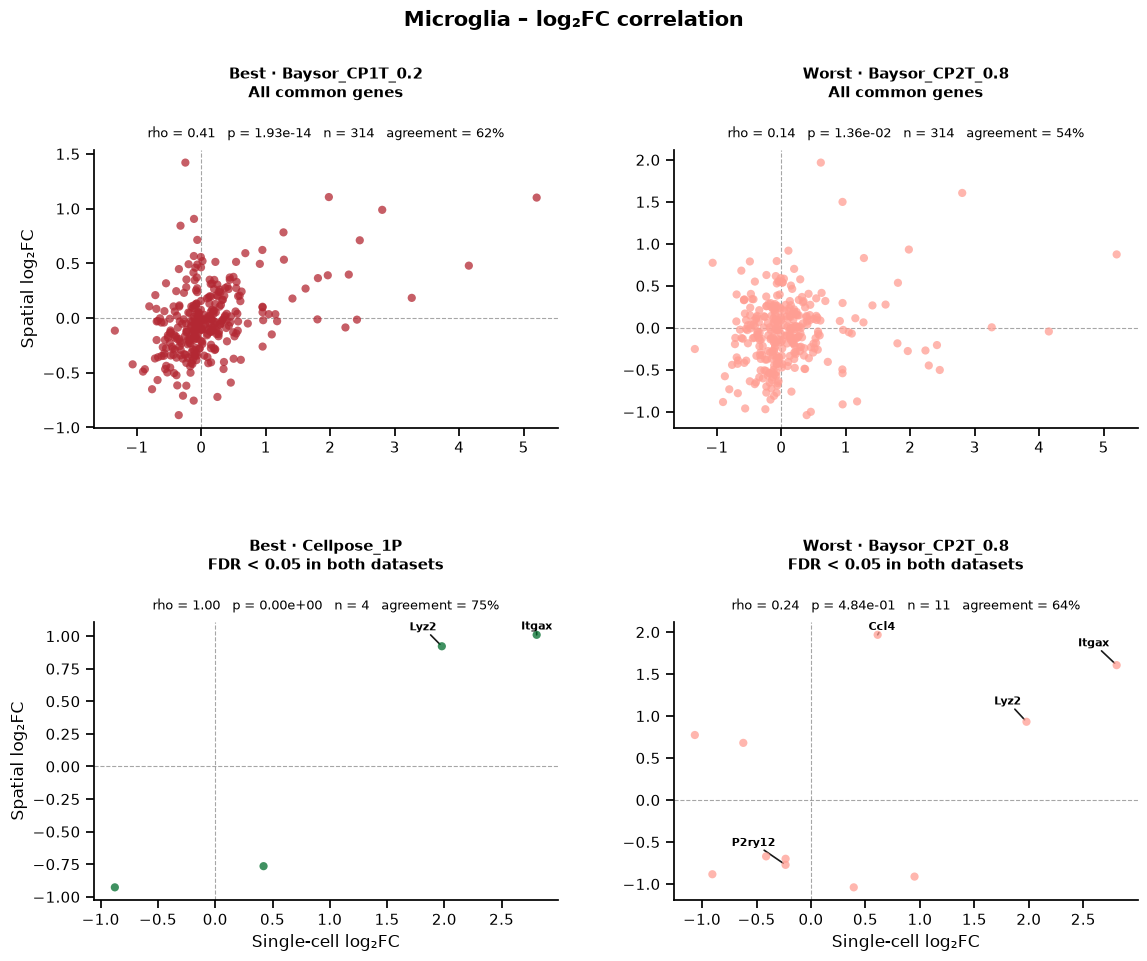

In [22]:
for cell_type in cell_types_to_plot:

    plot_gene_level_best_worst(
        cell_type=cell_type,
        raw_res=all_raw_results[cell_type],
        sig_res=all_sig_results[cell_type],
        marker_genes=marker_genes,
        method_colors=method_colors,
        method_display_names=method_display_names,
        alpha=alpha,
        min_genes=MIN_GENES_FOR_RANKING,
        save_dir=figure_dir,
    )

## 8. Direct spatial best/worst comparison

For each independently ranked pair, intersect the matched gene sets of both methods. In the significant analysis, genes must pass FDR in Jin and both selected spatial methods.

In [23]:
def plot_best_vs_worst_fc(
    cell_type,
    method_results,
    significant_only=False,
    alpha=0.05,
    min_genes=3,
    figsize=(7, 7),
    save_dir=None,
):
    """
    Compare spatial logFC between best and worst segmentation methods.
    """

    # --------------------------------------------------------------
    # Select best/worst
    # --------------------------------------------------------------

    best_method, worst_method = select_best_worst_methods(
        method_results,
        min_genes=min_genes,
    )

    if best_method is None or worst_method is None:
        return None

    # --------------------------------------------------------------
    # Get genes
    # --------------------------------------------------------------

    best_df = get_common_genes(
        method=best_method,
        cell_type=cell_type,
        significant_only=significant_only,
        alpha=alpha,
    ).copy()

    worst_df = get_common_genes(
        method=worst_method,
        cell_type=cell_type,
        significant_only=significant_only,
        alpha=alpha,
    ).copy()

    best_df = (
        best_df[
            ["gene", "logFC_spatial"]
        ]
        .rename(
            columns={
                "logFC_spatial": "logFC_best"
            }
        )
    )

    worst_df = (
        worst_df[
            ["gene", "logFC_spatial"]
        ]
        .rename(
            columns={
                "logFC_spatial": "logFC_worst"
            }
        )
    )

    paired = best_df.merge(
        worst_df,
        on="gene",
        how="inner",
    )

    paired = paired.dropna(
        subset=[
            "logFC_best",
            "logFC_worst",
        ]
    ).copy()

    n_genes = len(paired)

    if n_genes < min_genes:
        print(
            f"{cell_type}: only {n_genes} genes shared between "
            f"{display_method(best_method)} and {display_method(worst_method)} "
            f"(minimum required = {min_genes})."
        )
        return paired

    # --------------------------------------------------------------
    # Statistics
    # --------------------------------------------------------------

    rho, pvalue = safe_spearman(
        paired["logFC_best"],
        paired["logFC_worst"],
    )

    matching = (
        np.sign(paired["logFC_best"])
        ==
        np.sign(paired["logFC_worst"])
    )

    fraction_matching = (
        matching.sum() / n_genes
    )

    # --------------------------------------------------------------
    # Plot
    # --------------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=figsize
    )

    ax.scatter(
        paired["logFC_best"],
        paired["logFC_worst"],
        s=35,
        alpha=0.7,
        edgecolors="none",
    )

    ax.axhline(
        0,
        color="grey",
        linestyle="--",
        linewidth=0.8,
    )

    ax.axvline(
        0,
        color="grey",
        linestyle="--",
        linewidth=0.8,
    )

    # --------------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------------

    ax.set_xlabel(
        f"Best · {display_method(best_method)}\n"
        "Spatial log₂FC"
    )

    ax.set_ylabel(
        f"Worst · {display_method(worst_method)}\n"
        "Spatial log₂FC"
    )

    # --------------------------------------------------------------
    # Simple title
    # --------------------------------------------------------------

    ax.set_title(
        cell_type,
        fontsize=15,
        fontweight="bold",
        pad=20,
    )

    # --------------------------------------------------------------
    # Compact statistics
    # --------------------------------------------------------------

    ax.text(
        0.5,
        1.01,
        (
            f"rho = {rho:.2f}   "
            f"p = {pvalue:.2e}   "
            f"n = {n_genes}   "
            f"agreement = {fraction_matching:.0%}"
        ),
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
    )

    sns.despine(ax=ax)

    plt.tight_layout()

    # --------------------------------------------------------------
    # Save
    # --------------------------------------------------------------

    if save_dir is not None:

        save_dir = Path(save_dir)
        save_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        safe_cell_type = (
            str(cell_type)
            .replace(" ", "_")
            .replace("/", "_")
        )

        if significant_only:
            suffix = "FDR_significant"
        else:
            suffix = "all_genes"

        filename = (
            f"C_{safe_cell_type}_"
            f"best_vs_worst_{suffix}"
        )

        fig.savefig(
            save_dir / f"{filename}.png",
            dpi=300,
            bbox_inches="tight",
        )

        fig.savefig(
            save_dir / f"{filename}.pdf",
            bbox_inches="tight",
        )

    plt.show()

    return paired

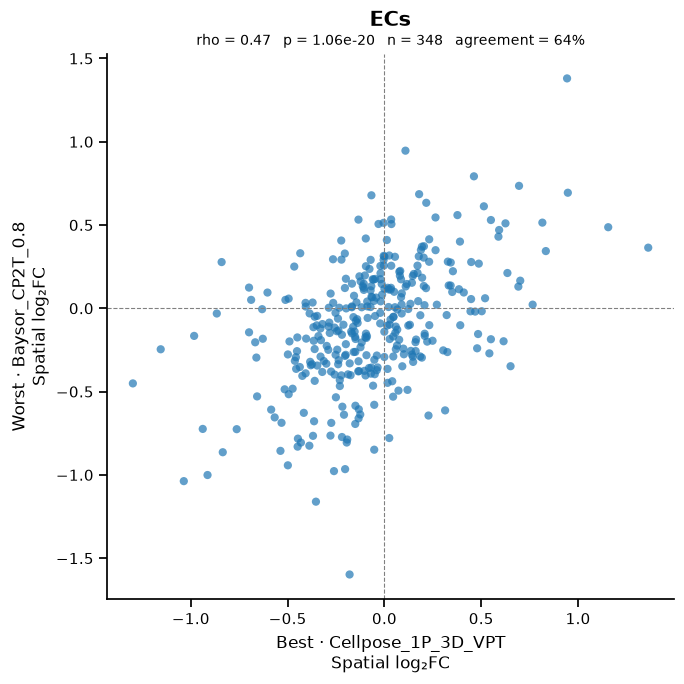

ECs: only 2 genes shared between Cellpose_1P and Proseg_3D_CP1P (minimum required = 3).


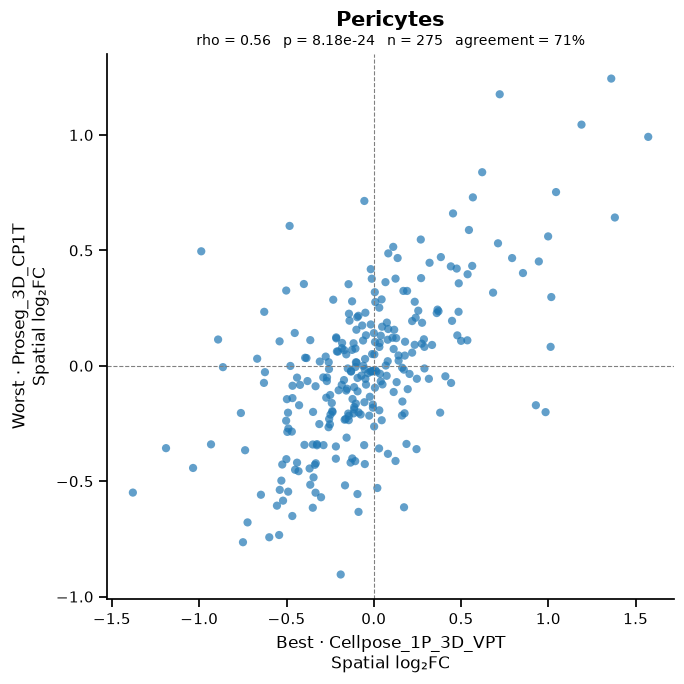

Pericytes: only 1 genes shared between Baysor_CP2T_0.8 and Proseg_3D_CP1P (minimum required = 3).


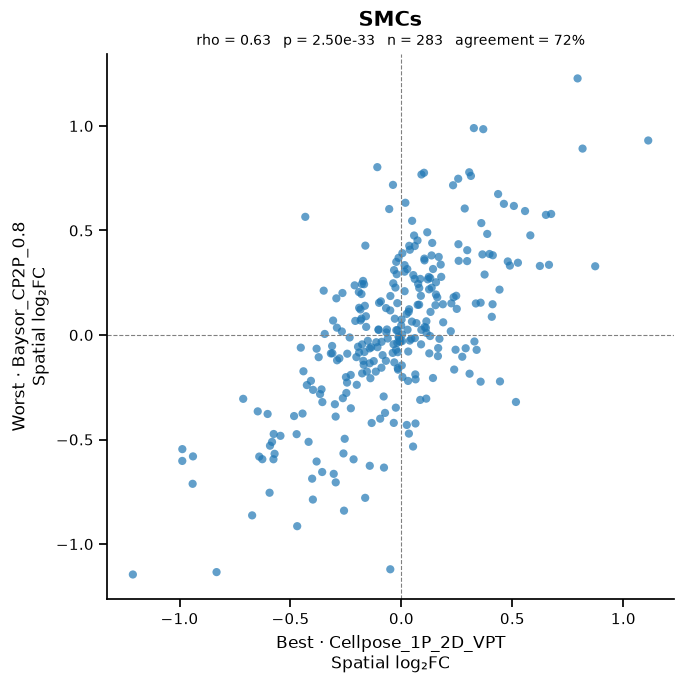

SMCs: only 2 genes shared between Cellpose_1_Merscope and Cellpose_1n (minimum required = 3).


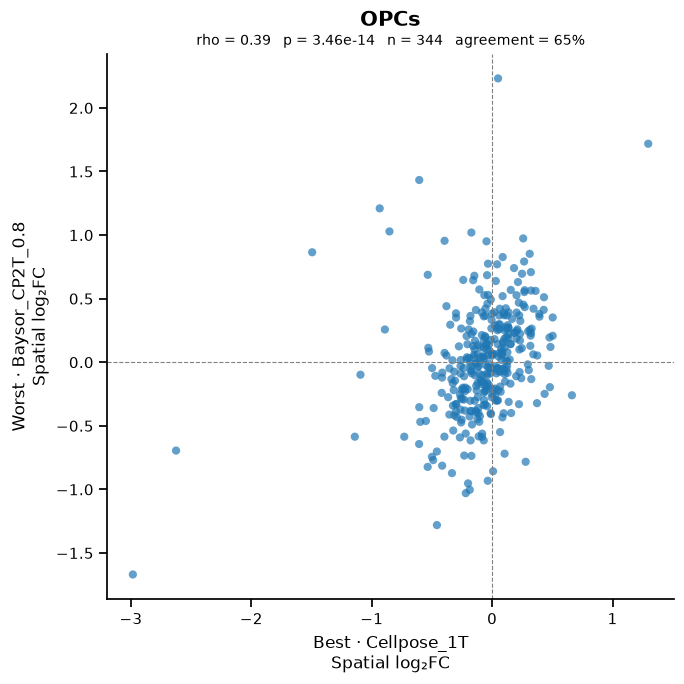

OPCs: only 1 genes shared between Baysor_CP1P_0.8 and Cellpose_1P_2D_VPT (minimum required = 3).


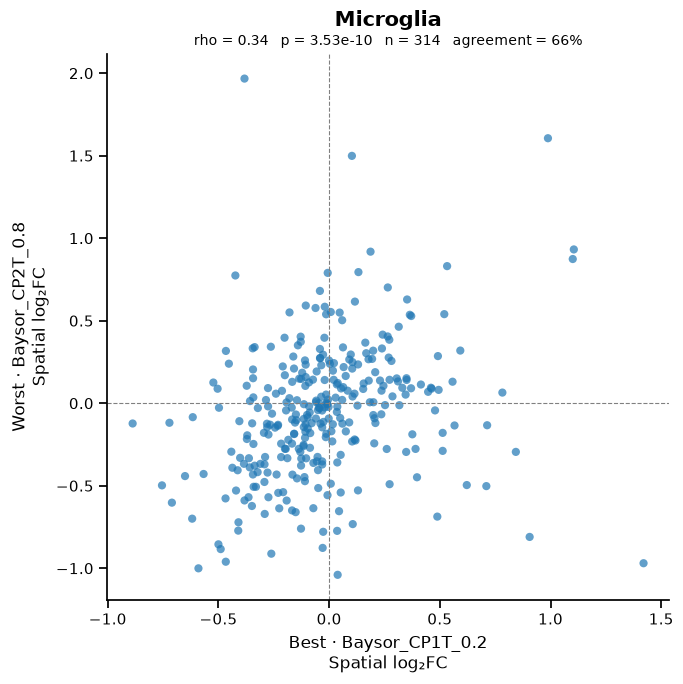

Microglia: only 2 genes shared between Cellpose_1P and Baysor_CP2T_0.8 (minimum required = 3).


In [24]:
best_vs_worst_fc_results = {}

for cell_type in cell_types_to_plot:

    # ==============================================================
    # 1. ALL COMMON GENES
    # ==============================================================

    paired_all = plot_best_vs_worst_fc(
        cell_type=cell_type,
        method_results=all_raw_results[cell_type],
        significant_only=False,
        alpha=alpha,
        min_genes=MIN_GENES_FOR_RANKING,
        save_dir=figure_dir,
    )

    # ==============================================================
    # 2. SIGNIFICANT IN BOTH DATASETS
    # ==============================================================

    paired_sig = plot_best_vs_worst_fc(
        cell_type=cell_type,
        method_results=all_sig_results[cell_type],
        significant_only=True,
        alpha=alpha,
        min_genes=MIN_GENES_FOR_RANKING,
        save_dir=figure_dir,
    )

    # ==============================================================
    # Store results
    # ==============================================================

    best_vs_worst_fc_results[cell_type] = {
        "all_common_genes": paired_all,
        "significant_both": paired_sig,
    }

    # ==============================================================
    # Save tables
    # ==============================================================

    if paired_all is not None:

        paired_all.to_csv(
            out_path
            / f"best_vs_worst_spatial_FC_all_common_genes_{cell_type}.csv",
            index=False,
        )

    if paired_sig is not None:

        paired_sig.to_csv(
            out_path
            / f"best_vs_worst_spatial_FC_FDR_significant_both_{cell_type}.csv",
            index=False,
        )